# Stage 3 — Portfolio Construction and Risk Engine

**Executive summary.** Stage 3 measures the *historical* risk of a fixed, equal-weight eight-stock portfolio (AAPL, MSFT, NVDA, JPM, XOM, JNJ, WMT, CAT; USD 100,000) on Stage 2 daily returns, 2015–2025: portfolio value paths, annualized volatility, 1-day historical VaR and CVaR, maximum drawdown, Euler volatility contributions, worst historical 1-day and 5-day episodes, and explicit risk-limit checks. Every estimator is ported from `src/rlstress/risk/` and `src/rlstress/stress/` and reconciled with the engine's saved outputs in `results/stage3/`.

**What it does not do:** it does not forecast returns or risk, optimize or recommend allocations, model transaction costs, taxes or financing, simulate hypothetical shocks (Stage 4) or train agents (Stage 5). Historical figures describe the sample, not the future.

**How later stages use it:** the Stage 4 environment values each simulated 5-day factor-shock path with the same constant-mix valuation, cumulative-loss and within-path drawdown definitions, and checks the same configured 5-day limits (10% loss, 10% drawdown); a plausible breach is what the Stage 5 PPO agent is rewarded for finding. The 1-day VaR/CVaR limits are evaluated on the training (estimation) window only.

## Part 1 — Purpose and methodology

| Item | Convention used throughout |
|---|---|
| Returns | Daily simple returns of Yahoo Finance adjusted close, $r_t = P_t/P_{t-1}-1$ (split- and dividend-adjusted at source ≈ total returns; Part 3) |
| Missing data | Complete case: a date is used only if all 8 stock returns exist; nothing is filled with zero |
| Portfolio | Fixed target weights 12.5% each; long only; fully invested; no costs, taxes or cash flows |
| Valuation | Constant mix (daily rebalanced) is the risk-engine convention; buy and hold is reported alongside for comparison |
| Timing | Capital invested once at the close of the trading day before the first return (2015-01-02) |
| Sign convention | VaR, CVaR, cumulative loss and limit observations are **positive losses**; drawdown is reported **negative** |
| Horizons | VaR/CVaR: 1 trading day. Stress windows and path limits: 5 trading days, compounded |
| Estimation sample | Training split 2015–2021 for calibration (risk limits, attribution); validation and test reported separately; full period descriptive only |
| Minimum sample | VaR/CVaR refused (NaN) below `risk.min_observations` = 250 returns |
| Limit rule | Breach if observed ≥ threshold − 1e-12 (configured `>=` rule; tolerance absorbs float error only) |

## Part 2 — Imports and configuration

### 1. Imports and project configuration

In [1]:
import json
import math
import tomllib
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "default.toml").is_file()), None
)
assert PROJECT_ROOT is not None, "config/default.toml not found; run the notebook from inside the project"
with (PROJECT_ROOT / "config" / "default.toml").open("rb") as fh:
    CONFIG = tomllib.load(fh)

portfolio_cfg, risk_cfg, data_cfg = CONFIG["portfolio"], CONFIG["risk"], CONFIG["data"]
WEIGHTS = pd.Series(portfolio_cfg["weights"], dtype=float, name="weight")
STOCKS = list(WEIGHTS.index)
CAPITAL = float(portfolio_cfg["initial_capital"])
CURRENCY = portfolio_cfg["base_currency"]
WEIGHT_TOL = float(portfolio_cfg["weight_tolerance"])
SPLITS = {k: (pd.Timestamp(s), pd.Timestamp(e)) for k, (s, e) in data_cfg["splits"].items()}
CONFIDENCES = [float(a) for a in risk_cfg["confidence_levels"]]
ANN = int(risk_cfg["annualization_days"])
MIN_OBS = int(risk_cfg["min_observations"])
TOL = float(risk_cfg["comparison_tolerance"])
HORIZON = int(risk_cfg["stress_horizon_days"])
N_WORST = int(risk_cfg["worst_windows"])
RETURNS_FILE = PROJECT_ROOT / "data" / "processed" / "returns" / f"daily_returns_processed_{data_cfg['start_date']}_{data_cfg['end_date']}.csv"
STAGE3_RESULTS = PROJECT_ROOT / risk_cfg["output_dir"]

EXPECTED = {"stocks": ["AAPL", "MSFT", "NVDA", "JPM", "XOM", "JNJ", "WMT", "CAT"], "capital": 100_000.0,
            "splits": {"train": ("2015-01-01", "2021-12-31"), "validation": ("2022-01-01", "2023-12-31"),
                       "test": ("2024-01-01", "2025-12-31")}}
assert STOCKS == EXPECTED["stocks"], STOCKS
assert CAPITAL == EXPECTED["capital"], CAPITAL
assert {k: (str(s.date()), str(e.date())) for k, (s, e) in SPLITS.items()} == EXPECTED["splits"]

assert 0 < WEIGHT_TOL < 1e-3, "weight tolerance must be in (0, 1e-3)"
assert all(0 < a < 1 for a in CONFIDENCES), "confidence levels must lie in (0, 1)"
assert ANN > 0 and MIN_OBS >= 1 and HORIZON >= 1 and N_WORST >= 1 and 0 <= TOL < 1e-6

SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
STOCK_COLORS = dict(zip(STOCKS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]))

display(pd.DataFrame({
    "setting": ["stocks", "initial capital", "weights", "rebalancing", "confidence levels", "annualization days",
                "min observations (VaR/CVaR)", "returns file (Stage 2)"] + [f"{k} split" for k in SPLITS],
    "value": [", ".join(STOCKS), f"{CAPITAL:,.0f} {CURRENCY}", ", ".join(f"{t} {w:.3f}" for t, w in WEIGHTS.items()),
              portfolio_cfg["rebalancing"], str(CONFIDENCES), ANN, MIN_OBS, str(RETURNS_FILE.relative_to(PROJECT_ROOT))]
             + [f"{s.date()} -> {e.date()}" for s, e in SPLITS.values()],
}).style.hide(axis="index"))

setting,value
stocks,"AAPL, MSFT, NVDA, JPM, XOM, JNJ, WMT, CAT"
initial capital,"100,000 USD"
weights,"AAPL 0.125, MSFT 0.125, NVDA 0.125, JPM 0.125, XOM 0.125, JNJ 0.125, WMT 0.125, CAT 0.125"
rebalancing,daily_constant_mix
confidence levels,"[0.95, 0.99]"
annualization days,252
min observations (VaR/CVaR),250
returns file (Stage 2),data/processed/returns/daily_returns_processed_2015-01-01_2025-12-31.csv
train split,2015-01-01 -> 2021-12-31
validation split,2022-01-01 -> 2023-12-31


## Part 3 — Data loading and integrity

### 2. Load Stage 2 data and integrity checks

In [2]:
import hashlib

candidates = sorted((PROJECT_ROOT / "data" / "processed" / "returns").glob("*.csv"))
display(pd.DataFrame({"file": [str(p.relative_to(PROJECT_ROOT)) for p in candidates],
                      "size_kb": [round(p.stat().st_size / 1024, 1) for p in candidates]}).style.hide(axis="index"))

if not RETURNS_FILE.is_file():
    raise FileNotFoundError(f"Stage 2 processed returns not found: {RETURNS_FILE}. Run stage_2.ipynb first.")

returns = pd.read_csv(RETURNS_FILE, parse_dates=["date"], index_col="date")
STOCK_COLS = [f"{t}_return" for t in STOCKS]

def integrity_report(frame, cols):
    """Structural checks on a return frame. Reports problems; never modifies or fills the data."""
    missing = [c for c in cols if c not in frame.columns]
    present = [c for c in cols if c in frame.columns]
    vals = frame[present].apply(pd.to_numeric, errors="coerce")
    arr = vals.to_numpy(dtype=float)
    incomplete = vals.isna().any(axis=1)
    rows = [
        ("required columns present", not missing, f"missing: {missing}" if missing else f"{len(present)} of {len(cols)}"),
        ("DatetimeIndex", isinstance(frame.index, pd.DatetimeIndex), str(frame.index.dtype)),
        ("dates unique", frame.index.is_unique, f"{int(frame.index.duplicated().sum())} duplicate(s)"),
        ("dates sorted ascending", frame.index.is_monotonic_increasing, ""),
        ("float dtype in every column", all(pd.api.types.is_float_dtype(frame[c]) for c in present), ""),
        ("no infinite values", not np.isinf(arr).any(), f"{int(np.isinf(arr).sum())} inf"),
        ("no return below -100%", not (arr < -1).any(), f"min {np.nanmin(arr):+.4f}, max {np.nanmax(arr):+.4f}" if arr.size else ""),
        ("consistent coverage (missing rows are missing for every asset)", incomplete.equals(vals.isna().all(axis=1)),
         f"{int(incomplete.sum())} incomplete row(s): {[d.date().isoformat() for d in frame.index[incomplete]][:5]}"),
    ]
    return pd.DataFrame(rows, columns=["check", "pass", "detail"])

integrity = integrity_report(returns, STOCK_COLS)
display(integrity.style.hide(axis="index"))
assert integrity["pass"].all(), f"data integrity failed: {integrity.loc[~integrity['pass'], 'check'].tolist()}"

provenance = pd.DataFrame({"item": ["file", "sha256", "rows x columns", "date range", "written by", "built from"],
                           "value": [str(RETURNS_FILE.relative_to(PROJECT_ROOT)), hashlib.sha256(RETURNS_FILE.read_bytes()).hexdigest(),
                                     f"{returns.shape[0]} x {returns.shape[1]}", f"{returns.index.min().date()} -> {returns.index.max().date()}",
                                     "stage_2.ipynb (pct_change of adjusted close, NaN kept)", "data/raw/stocks/*.csv (Yahoo Finance, auto_adjust=False)"]})
display(provenance.style.hide(axis="index"))
display(returns[STOCK_COLS].isna().sum().to_frame("missing").T)
display(returns[STOCK_COLS].head(3))

file,size_kb
data/processed/returns/daily_returns_processed_2015-01-01_2025-12-31.csv,725.200000
data/processed/returns/macro_changes.csv,228.500000
data/processed/returns/market_indicator_returns.csv,494.400000
data/processed/returns/model_returns_processed_2015-01-01_2025-12-31.csv,725.200000
data/processed/returns/stock_returns.csv,956.300000
data/processed/returns/vix_changes.csv,137.800000


check,pass,detail
required columns present,True,8 of 8
DatetimeIndex,True,datetime64[us]
dates unique,True,0 duplicate(s)
dates sorted ascending,True,
float dtype in every column,True,
no infinite values,True,0 inf
no return below -100%,True,"min -0.1876, max +0.2981"
consistent coverage (missing rows are missing for every asset),True,1 incomplete row(s): ['2015-01-02']


item,value
file,data/processed/returns/daily_returns_processed_2015-01-01_2025-12-31.csv
sha256,901ad548e51fe277c9185e6ca3c5c537eb348949f5a5dba31d7955e3ea761fdc
rows x columns,2766 x 12
date range,2015-01-02 -> 2025-12-31
written by,"stage_2.ipynb (pct_change of adjusted close, NaN kept)"
built from,"data/raw/stocks/*.csv (Yahoo Finance, auto_adjust=False)"


,AAPL_return,MSFT_return,NVDA_return,JPM_return,XOM_return,JNJ_return,WMT_return,CAT_return
missing,1,1,1,1,1,1,1,1


,AAPL_return,MSFT_return,NVDA_return,JPM_return,XOM_return,JNJ_return,WMT_return,CAT_return
date,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,-0.028172,-0.009196,-0.016890,-0.031045,-0.027362,-0.006984,-0.002910,-0.052786
2015-01-06,0.000094,-0.014677,-0.030318,-0.025929,-0.005316,-0.004914,0.007706,-0.006435


### 3. Complete-case portfolio data and split assignment

In [3]:
asset_returns_all = returns[STOCK_COLS].rename(columns=lambda c: c.removesuffix("_return"))
complete = asset_returns_all.notna().all(axis=1)
asset_returns = asset_returns_all[complete]          # complete-case rows only; nothing filled
removed = asset_returns_all.index[~complete]
print(f"Rows in: {len(asset_returns_all)}   removed (any stock missing): {len(removed)}   kept: {len(asset_returns)}")
print("Removed dates:", [d.date().isoformat() for d in removed])

def split_label(index):
    lab = pd.Series(pd.NA, index=index, dtype="object")
    for name, (s, e) in SPLITS.items():
        lab[(index >= s) & (index <= e)] = name
    return lab

SPLIT_OF = split_label(asset_returns.index)
assert SPLIT_OF.notna().all(), "a complete row falls outside every split"
display(SPLIT_OF.value_counts().reindex(list(SPLITS)).to_frame("rows").T)

# Split assignment must equal the configured date boundaries exactly; nothing outside the splits.
for name, (s, e) in SPLITS.items():
    in_range = (asset_returns.index >= s) & (asset_returns.index <= e)
    assert int(in_range.sum()) == int((SPLIT_OF == name).sum()), f"{name}: split assignment mismatch"
assert not asset_returns.isna().any().any() and np.isfinite(asset_returns.to_numpy()).all()
assert list(asset_returns.columns) == STOCKS, "asset columns must follow the portfolio ticker order"
print("Every complete row is assigned to exactly one configured split; no NaN or infinite returns remain.")

Rows in: 2766   removed (any stock missing): 1   kept: 2765
Removed dates: ['2015-01-02']


,train,validation,test
rows,1762,501,502


Every complete row is assigned to exactly one configured split; no NaN or infinite returns remain.


### 4. Data provenance and corporate actions
Traces the Stage 2 returns back to the raw Yahoo Finance files (`data/raw/stocks/*.csv`, downloaded 2026-10-18 with `auto_adjust=False`, `actions=True`).

- **Verified from the files below:** `close` is split-adjusted and `adj_close` is split- *and* dividend-adjusted; every split in the sample (incl. NVDA 4:1 2021-07-20 and 10:1 2024-06-10) produces an ordinary return on the split day; adjusted-close returns equal (close + dividend)/previous close − 1 up to Yahoo's dividend-factor rounding; Stage 2 applies no further adjustment, so nothing is double-counted. The returns are therefore **approximate total returns**.
- **Assumed, not verifiable here:** Yahoo's adjustment factors are correct; dividends are reinvested at the ex-date close with no withholding tax; prices are as of the download date and Yahoo may restate history; no second data source (e.g. CRSP) is available for cross-checking.

In [4]:
RAW_STOCK_DIR = PROJECT_ROOT / data_cfg["paths"]["raw_dir"] / "stocks"
raw = {t: pd.read_csv(RAW_STOCK_DIR / f"{t}.csv", parse_dates=["date"], index_col="date") for t in STOCKS}
meta = {t: json.loads((RAW_STOCK_DIR / f"{t}.meta.json").read_text()) for t in STOCKS}

prov_rows = []
for t in STOCKS:
    r = raw[t]
    adj_ret = r["adj_close"].pct_change(fill_method=None)
    close_plus_div = (r["close"] + r["dividends"]) / r["close"].shift(1) - 1
    split_days = r.index[r["stock_splits"] != 0]
    prov_rows.append({
        "ticker": t, "source": meta[t]["source"], "auto_adjust": meta[t]["metadata"]["auto_adjust"],
        "retrieved_utc": meta[t]["retrieved_at_utc"][:10],
        "splits_in_source": ", ".join(f"{d.date()} {r['stock_splits'][d]:g}:1" for d in split_days) or "none",
        "max_abs_return_on_split_days": adj_ret.loc[split_days].abs().max() if len(split_days) else np.nan,
        "dividend_days": int((r["dividends"] > 0).sum()),
        "max_abs_adj_vs_close_plus_div": (adj_ret - close_plus_div).abs().max(),
        "price_only_growth": r["close"].iloc[-1] / r["close"].iloc[0],
        "total_return_growth": r["adj_close"].iloc[-1] / r["adj_close"].iloc[0],
    })
prov = pd.DataFrame(prov_rows).set_index("ticker")
display(prov.style.format({"max_abs_return_on_split_days": "{:.2%}", "max_abs_adj_vs_close_plus_div": "{:.4%}",
                           "price_only_growth": "{:,.2f}x", "total_return_growth": "{:,.2f}x"}, na_rep="-"))

nvda = raw["NVDA"].loc["2024-06-05":"2024-06-12", ["close", "adj_close", "dividends", "stock_splits"]]
nvda["adj_close_return"] = raw["NVDA"]["adj_close"].pct_change(fill_method=None).loc[nvda.index]
display(nvda.style.format({"close": "{:.3f}", "adj_close": "{:.3f}", "dividends": "{:.2f}", "stock_splits": "{:g}",
                           "adj_close_return": "{:+.2%}"}).set_caption("NVDA around the 10-for-1 split (2024-06-10): prices already split-adjusted in the source"))

raw_adj = pd.concat({t: raw[t]["adj_close"] for t in STOCKS}, axis=1)
raw_returns = raw_adj.pct_change(fill_method=None)
# The Stage 2 file stores exact pct_change values; pandas' default CSV float parser (used by Stage 3 and the engine)
# is not round-trip exact, so compare bit-for-bit with a round-trip read and report the default-parser difference.
stage2_exact = pd.read_csv(RETURNS_FILE, parse_dates=["date"], index_col="date", float_precision="round_trip")[STOCK_COLS]
chain_equal = np.array_equal(raw_returns.to_numpy(), stage2_exact.to_numpy(), equal_nan=True)
parse_diff = float(np.nanmax(np.abs(raw_returns.to_numpy() - asset_returns_all[STOCKS].to_numpy())))
print(f"Default-parser read of the Stage 2 file differs from exact returns by at most {parse_diff:.1e} (float parsing, immaterial)")
cal = returns.index
holidays = ["2015-01-01", "2018-12-05", "2024-12-25", "2025-01-09", "2025-12-25"]
provenance_checks = {
    "Stage 2 returns == pct_change(raw adj_close) bit-for-bit, no further adjustment": chain_equal,
    "default-parser read within 1e-15 of exact returns": parse_diff <= 1e-15,
    "all 8 raw files share one date index": all(raw[t].index.equals(raw[STOCKS[0]].index) for t in STOCKS),
    "split-day returns all below 5% (no unadjusted split jumps)": bool((prov["max_abs_return_on_split_days"].fillna(0) < 0.05).all()),
    "adj_close return == (close + dividend) / close_prev - 1 within 0.2% (dividend-day factor rounding)": bool((prov["max_abs_adj_vs_close_plus_div"] < 0.002).all()),
    "calendar: no weekends, no duplicates": bool((cal.dayofweek < 5).all() and cal.is_unique),
    "calendar: market holidays/closures absent " + ", ".join(holidays): not any(pd.Timestamp(d) in cal for d in holidays),
    "first row 2015-01-02 (first trading day of 2015), last row 2025-12-31": cal[0] == pd.Timestamp("2015-01-02") and cal[-1] == pd.Timestamp("2025-12-31"),
}
for k, v in provenance_checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
print("Trading days per year:", cal.year.value_counts().sort_index().to_dict())
assert all(provenance_checks.values())

,source,auto_adjust,retrieved_utc,splits_in_source,max_abs_return_on_split_days,dividend_days,max_abs_adj_vs_close_plus_div,price_only_growth,total_return_growth
ticker,,,,,,,,,
AAPL,yahoo_finance,False,2026-10-18,2020-08-31 4:1,3.39%,44,0.0124%,9.95x,11.22x
MSFT,yahoo_finance,False,2026-10-18,none,-,44,0.0135%,10.34x,12.13x
NVDA,yahoo_finance,False,2026-10-18,"2021-07-20 4:1, 2024-06-10 10:1",0.89%,44,0.0093%,370.59x,386.12x
JPM,yahoo_finance,False,2026-10-18,none,-,44,0.0458%,5.16x,6.90x
XOM,yahoo_finance,False,2026-10-18,none,-,44,0.0523%,1.30x,2.08x
JNJ,yahoo_finance,False,2026-10-18,none,-,44,0.0192%,1.98x,2.69x
WMT,yahoo_finance,False,2026-10-18,2024-02-26 3:1,1.85%,44,0.0201%,3.89x,4.80x
CAT,yahoo_finance,False,2026-10-18,none,-,44,0.0403%,6.23x,8.26x


,close,adj_close,dividends,stock_splits,adj_close_return
date,,,,,
2024-06-05 00:00:00,122.440,122.092,0.00,0,+5.16%
2024-06-06 00:00:00,120.998,120.654,0.00,0,-1.18%
2024-06-07 00:00:00,120.888,120.544,0.00,0,-0.09%
2024-06-10 00:00:00,121.790,121.444,0.00,10,+0.75%
2024-06-11 00:00:00,120.910,120.576,0.01,0,-0.71%
2024-06-12 00:00:00,125.200,124.854,0.00,0,+3.55%


Default-parser read of the Stage 2 file differs from exact returns by at most 1.0e-16 (float parsing, immaterial)
PASS  Stage 2 returns == pct_change(raw adj_close) bit-for-bit, no further adjustment
PASS  default-parser read within 1e-15 of exact returns
PASS  all 8 raw files share one date index
PASS  split-day returns all below 5% (no unadjusted split jumps)
PASS  adj_close return == (close + dividend) / close_prev - 1 within 0.2% (dividend-day factor rounding)
PASS  calendar: no weekends, no duplicates
PASS  calendar: market holidays/closures absent 2015-01-01, 2018-12-05, 2024-12-25, 2025-01-09, 2025-12-25
PASS  first row 2015-01-02 (first trading day of 2015), last row 2025-12-31
Trading days per year: {2015: 252, 2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250}


## Part 4 — Portfolio construction and valuation

### 5. Portfolio configuration

In [5]:
def validate_capital(capital):
    """Positive, finite initial capital."""
    try:
        c = float(capital)
    except (TypeError, ValueError):
        raise ValueError(f"capital must be a number, got {capital!r}") from None
    if not math.isfinite(c) or c <= 0:
        raise ValueError(f"capital must be positive and finite, got {capital!r}")
    return c

def validate_weights(weights, assets=None, tol=WEIGHT_TOL):
    """Finite, non-negative weights summing to 1 within tol, unique tickers, optionally matching `assets` exactly."""
    if not isinstance(weights, pd.Series) or len(weights) == 0:
        raise ValueError("weights must be a non-empty pandas Series indexed by ticker")
    if weights.index.has_duplicates:
        raise ValueError(f"duplicate tickers in weights: {weights.index[weights.index.duplicated()].tolist()}")
    w = pd.to_numeric(weights, errors="coerce").astype(float)
    if not np.isfinite(w.to_numpy()).all():
        raise ValueError("weights must be finite numbers")
    if (w < 0).any():
        raise ValueError(f"negative weights (long-only portfolio): {w[w < 0].to_dict()}")
    if abs(w.sum() - 1.0) > tol:
        raise ValueError(f"weights sum to {w.sum():.12f}, not 1 within {tol:g}")
    if assets is not None and set(assets) != set(w.index):
        raise ValueError(f"weights {sorted(w.index)} do not match assets {sorted(assets)}")
    return w

WEIGHTS = validate_weights(WEIGHTS, assets=STOCKS)
CAPITAL = validate_capital(CAPITAL)

portfolio_table = pd.DataFrame({"ticker": STOCKS, "weight": WEIGHTS.values,
                                f"allocation_{CURRENCY}": WEIGHTS.values * CAPITAL})
display(portfolio_table.style.format({"weight": "{:.4f}", f"allocation_{CURRENCY}": "{:,.2f}"}).hide(axis="index"))

assert len(WEIGHTS) == 8, f"expected 8 stocks, got {len(WEIGHTS)}"
assert math.isclose(portfolio_table[f"allocation_{CURRENCY}"].sum(), CAPITAL)
print(f"8 stocks | weights finite, >= 0 | sum = {WEIGHTS.sum():.12f} (tol {WEIGHT_TOL:g}) | capital = {CAPITAL:,.2f} {CURRENCY}: all valid")

ticker,weight,allocation_USD
AAPL,0.1250,"12,500.00"
MSFT,0.1250,"12,500.00"
NVDA,0.1250,"12,500.00"
JPM,0.1250,"12,500.00"
XOM,0.1250,"12,500.00"
JNJ,0.1250,"12,500.00"
WMT,0.1250,"12,500.00"
CAT,0.1250,"12,500.00"


8 stocks | weights finite, >= 0 | sum = 1.000000000000 (tol 1e-08) | capital = 100,000.00 USD: all valid


### 6. Portfolio daily returns
$r_{p,t}=\sum_i w_i r_{i,t}$ on complete-case dates, with weights aligned to columns by ticker name.

In [6]:
def check_return_values(values, what="returns"):
    """Non-empty, no NaN, finite, no return below -100%."""
    x = np.asarray(values, dtype=float)
    if x.size == 0:
        raise ValueError(f"{what}: no observations")
    if np.isnan(x).any():
        raise ValueError(f"{what} contain NaN (apply the complete-case policy first; never zero-fill)")
    if np.isinf(x).any():
        raise ValueError(f"{what} contain infinity")
    if (x < -1.0).any():
        raise ValueError(f"{what}: values below -100% are impossible for long equity positions")
    return x

def validate_returns(r):
    """Dated returns: DatetimeIndex, unique, ascending, valid values."""
    if not isinstance(r.index, pd.DatetimeIndex):
        raise ValueError("returns must have a DatetimeIndex")
    if not r.index.is_unique:
        raise ValueError("duplicate return dates")
    if not r.index.is_monotonic_increasing:
        raise ValueError("return dates are not sorted ascending")
    check_return_values(r)

def portfolio_daily_returns(asset_r, weights):
    w = validate_weights(weights, assets=list(asset_r.columns))
    ordered = asset_r[list(w.index)]
    validate_returns(ordered)
    return (ordered * w).sum(axis=1).rename("portfolio_return")

portfolio_returns = portfolio_daily_returns(asset_returns[STOCKS], WEIGHTS)

display(portfolio_returns.head().to_frame())
display(portfolio_returns.tail().to_frame())
display(portfolio_returns.describe().to_frame().T)
print("Observations:", len(portfolio_returns))

,portfolio_return
date,
2015-01-05,-0.021918
2015-01-06,-0.009974
2015-01-07,0.012486
2015-01-08,0.022958
2015-01-09,-0.007507


,portfolio_return
date,
2025-12-24,0.003905
2025-12-26,0.000305
2025-12-29,-0.001703
2025-12-30,-0.001648
2025-12-31,-0.004901


,count,mean,std,min,25%,50%,75%,max
portfolio_return,2765.0,0.000999,0.012208,-0.110701,-0.004453,0.001167,0.007056,0.103522


Observations: 2765


### 7. Portfolio value
**Constant mix** (risk-engine convention): weights are reset to 12.5% at every close, so $V_t=V_{t-1}(1+r_{p,t})$. Assumes free, instantaneous daily rebalancing at closing prices, fractional shares, no costs, taxes, financing or cash flows. **Buy and hold** (comparison only): $w_iV_0$ is invested once and each holding grows with its own returns, $H_{i,t}=w_iV_0\prod_{s\le t}(1+r_{i,s})$, with no rebalancing, so weights drift towards the best performers. No transaction costs are added to either baseline.

**Timing:** capital is invested once at the close of the base date $t_0$ = the trading day before the first complete return (2015-01-02, the first row of the Stage 2 calendar, whose own return is undefined). The first return $P_{2015\text{-}01\text{-}05}/P_{2015\text{-}01\text{-}02}-1$ is applied exactly once, and each value path has one more point than there are returns.

Base date (investment close): 2015-01-02 | first return: 2015-01-05 | last return: 2025-12-31 | 2765 returns, 2766 values per path


path,start_date,start_value,end_date,final_value,total_return_pct
constant mix (daily rebalanced),2015-01-02,"100,000.00",2025-12-31,"1,286,726.64","1,186.7%"
buy and hold (weights drift),2015-01-02,"100,000.00",2025-12-31,"5,427,439.87","5,327.4%"


,initial_weight,initial_holding,growth_multiple,final_holding,final_weight
AAPL,0.125,"12,500.00",11.22x,"140,205.98",2.58%
MSFT,0.125,"12,500.00",12.13x,"151,667.95",2.79%
NVDA,0.125,"12,500.00",386.12x,"4,826,491.13",88.93%
JPM,0.125,"12,500.00",6.90x,"86,208.70",1.59%
XOM,0.125,"12,500.00",2.08x,"25,972.56",0.48%
JNJ,0.125,"12,500.00",2.69x,"33,615.18",0.62%
WMT,0.125,"12,500.00",4.80x,"59,977.22",1.11%
CAT,0.125,"12,500.00",8.26x,"103,301.16",1.90%


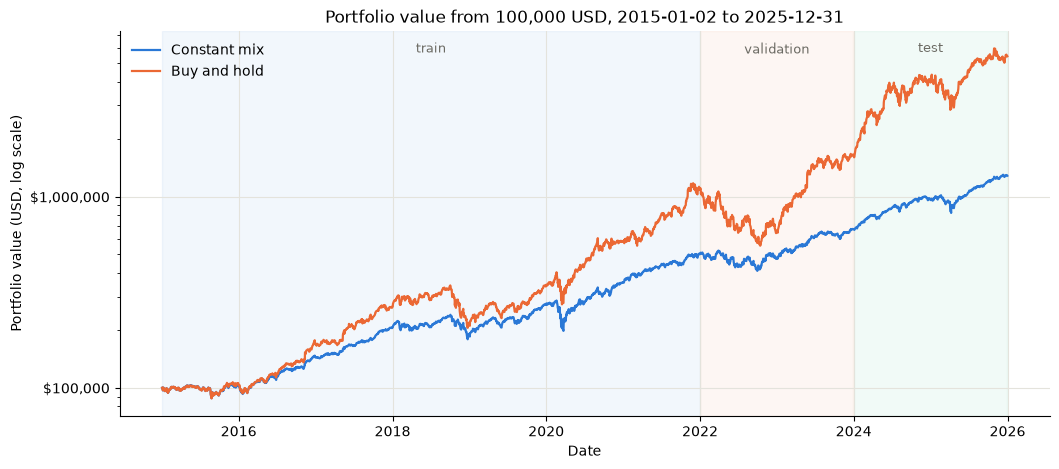

In [7]:
def base_date_for(calendar, first_date):
    """Trading date immediately before first_date (capital invested at that close)."""
    if not isinstance(calendar, pd.DatetimeIndex) or not calendar.is_unique or not calendar.is_monotonic_increasing:
        raise ValueError("calendar must be a unique, ascending DatetimeIndex")
    earlier = calendar[calendar < pd.Timestamp(first_date)]
    if len(earlier) == 0:
        raise ValueError(f"no trading date precedes {first_date.date()}")
    return earlier[-1]

def validate_valuation_inputs(r, base_date):
    """Reject inputs that would silently corrupt a value path (same rules as the Stage 3 engine)."""
    validate_returns(r)
    if pd.Timestamp(base_date) >= r.index[0]:
        raise ValueError(f"base date {pd.Timestamp(base_date).date()} must precede the first return {r.index[0].date()}")

def constant_mix_value(r_p, capital, base_date):
    """V_0 = capital at the base-date close; V_t = V_(t-1) (1 + r_p,t)."""
    capital = validate_capital(capital)
    validate_valuation_inputs(r_p, base_date)
    growth = np.cumprod(1.0 + r_p.to_numpy(dtype=float))
    idx = pd.DatetimeIndex([base_date]).append(r_p.index)
    return pd.Series(np.concatenate([[capital], capital * growth]), index=idx, name="portfolio_value")

def buy_and_hold_value(asset_r, weights, capital, base_date):
    """Holding_i,t = w_i V_0 prod_{s<=t}(1 + r_i,s); no rebalancing; total = sum of holdings."""
    capital = validate_capital(capital)
    weights = validate_weights(weights, assets=list(asset_r.columns))
    ordered = asset_r[list(weights.index)]
    validate_valuation_inputs(ordered, base_date)
    start = weights.to_numpy(dtype=float) * capital
    holdings = np.vstack([start, np.cumprod(1.0 + ordered.to_numpy(dtype=float), axis=0) * start])
    out = pd.DataFrame(holdings, index=pd.DatetimeIndex([base_date]).append(ordered.index), columns=list(weights.index))
    out["total"] = out.sum(axis=1)
    final_w = out[list(weights.index)].iloc[-1] / out["total"].iloc[-1]
    if not math.isclose(final_w.sum(), 1.0, abs_tol=1e-12):
        raise ValueError("buy-and-hold holdings do not reconcile with the total")
    return out

CALENDAR = returns.index                                  # every trading date in the Stage 2 data (incl. 2015-01-02)
BASE_DATE = base_date_for(CALENDAR, portfolio_returns.index[0])
portfolio_value = constant_mix_value(portfolio_returns, CAPITAL, BASE_DATE)
bh = buy_and_hold_value(asset_returns, WEIGHTS, CAPITAL, BASE_DATE)
buy_hold_value = bh["total"].rename("buy_and_hold_value")

assert portfolio_value.index.equals(buy_hold_value.index), "value paths are not aligned"
assert len(portfolio_value) == len(portfolio_returns) + 1 and portfolio_value.index.is_unique
print(f"Base date (investment close): {BASE_DATE.date()} | first return: {portfolio_returns.index[0].date()} | "
      f"last return: {portfolio_returns.index[-1].date()} | {len(portfolio_returns)} returns, {len(portfolio_value)} values per path")

summary_values = pd.DataFrame({
    "path": ["constant mix (daily rebalanced)", "buy and hold (weights drift)"],
    "start_date": [BASE_DATE.date()] * 2,
    "start_value": [portfolio_value.iloc[0], buy_hold_value.iloc[0]],
    "end_date": [portfolio_value.index[-1].date()] * 2,
    "final_value": [portfolio_value.iloc[-1], buy_hold_value.iloc[-1]],
})
summary_values["total_return_pct"] = (summary_values["final_value"] / summary_values["start_value"] - 1) * 100
display(summary_values.style.format({"start_value": "{:,.2f}", "final_value": "{:,.2f}", "total_return_pct": "{:,.1f}%"})
        .hide(axis="index"))

final_holdings = bh[STOCKS].iloc[-1]
final_weights = final_holdings / bh["total"].iloc[-1]
weights_table = pd.DataFrame({"initial_weight": WEIGHTS[STOCKS], "initial_holding": bh[STOCKS].iloc[0],
                              "growth_multiple": final_holdings / bh[STOCKS].iloc[0],
                              "final_holding": final_holdings, "final_weight": final_weights})
display(weights_table.style.format({"initial_weight": "{:.3f}", "initial_holding": "{:,.2f}", "growth_multiple": "{:,.2f}x",
                                    "final_holding": "{:,.2f}", "final_weight": "{:.2%}"})
        .set_caption("Buy and hold: growth of each holding (no rebalancing)"))
assert abs(WEIGHTS.sum() - 1) <= 1e-8 and abs(final_weights.sum() - 1) <= 1e-12
assert math.isclose(final_holdings.sum(), bh["total"].iloc[-1], rel_tol=1e-15)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(portfolio_value.index, portfolio_value, color="#2a78d6", linewidth=1.6, label="Constant mix")
ax.plot(buy_hold_value.index, buy_hold_value, color="#eb6834", linewidth=1.6, label="Buy and hold")
for name, (s, e) in SPLITS.items():
    ax.axvspan(s, e, color=SPLIT_COLORS[name], alpha=0.06)
    ax.text(s + (e - s) / 2, 0.97, name, transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="#6b6a63")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_ylabel(f"Portfolio value ({CURRENCY}, log scale)")
ax.set_xlabel("Date")
ax.set_title(f"Portfolio value from {CAPITAL:,.0f} {CURRENCY}, {BASE_DATE.date()} to {portfolio_value.index[-1].date()}")
ax.legend(frameon=False, loc="upper left")
plt.show()

## Part 5 — Risk metrics
All 1-day metrics use the constant-mix portfolio returns of the stated period; losses are positive, drawdowns negative.

### 8. Annualized volatility
$\sigma_{annual}=\operatorname{std}(r_p, ddof=1)\sqrt{252}$ per split (at least 2 observations).

period,start,end,observations,daily_vol_pct,annual_vol_pct
train,2015-01-05,2021-12-31,1762,1.267%,20.12%
validation,2022-01-03,2023-12-29,501,1.259%,19.98%
test,2024-01-02,2025-12-31,502,0.997%,15.83%


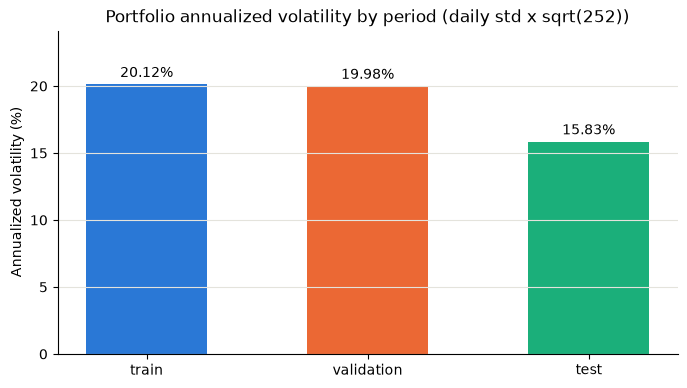

In [8]:
def annualized_volatility(r, periods=ANN, min_obs=2):
    """Sample std (ddof=1) of daily returns times sqrt(periods)."""
    x = check_return_values(r, "volatility input")
    if len(x) < max(2, min_obs):
        raise ValueError(f"volatility needs at least {max(2, min_obs)} observations, got {len(x)}")
    return float(pd.Series(x).std(ddof=1) * math.sqrt(periods))   # same estimator as pandas .std used elsewhere

SPLIT_RETURNS = {name: portfolio_returns[SPLIT_OF == name] for name in SPLITS}

vol_table = pd.DataFrame([
    {"period": name, "start": r.index.min().date(), "end": r.index.max().date(), "observations": len(r),
     "daily_vol_pct": r.std(ddof=1) * 100, "annual_vol_pct": annualized_volatility(r) * 100}
    for name, r in SPLIT_RETURNS.items()
])
display(vol_table.style.format({"daily_vol_pct": "{:.3f}%", "annual_vol_pct": "{:.2f}%"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(vol_table["period"], vol_table["annual_vol_pct"], color=[SPLIT_COLORS[p] for p in vol_table["period"]], width=0.55)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in vol_table["annual_vol_pct"]], padding=3)
ax.set_ylabel("Annualized volatility (%)")
ax.set_title(f"Portfolio annualized volatility by period (daily std x sqrt({ANN}))")
ax.set_ylim(0, vol_table["annual_vol_pct"].max() * 1.2)
ax.grid(axis="x", visible=False)
plt.show()

### 9. Historical Value at Risk
1-day historical VaR, $VaR_\alpha=-r_{(k)}$ with $k=\lceil n(1-\alpha)\rceil$ on ascending returns (inverted empirical CDF). Positive = loss. Refused (NaN) below 250 observations.

In [9]:
def tail_mass(n, alpha):
    return round(n * (1.0 - alpha), 9)            # removes float noise, e.g. 100 * 0.05 = 5.000000000000004$

def validate_alpha(alpha):
    a = float(alpha)
    if not 0.0 < a < 1.0:
        raise ValueError(f"confidence level must satisfy 0 < alpha < 1, got {alpha!r}")
    return a

def historical_var(r, alpha, min_obs=MIN_OBS):
    """1-day VaR = -r_(k), k = ceil(n(1-alpha)), returns sorted ascending (inverted empirical CDF)."""
    alpha = validate_alpha(alpha)
    check_return_values(r, "VaR input")
    if len(r) < min_obs:
        return float("nan")                        # refused: too few observations
    x = np.sort(r.to_numpy(dtype=float))
    k = max(1, math.ceil(tail_mass(len(x), alpha)))
    return -float(x[k - 1])

var_rows = []
for name, r in SPLIT_RETURNS.items():
    for a in CONFIDENCES:
        v = historical_var(r, a)
        var_rows.append({"period": name, "horizon": "1 day", "confidence": f"{a:.0%}", "observations": len(r),
                         "order_index_k": max(1, math.ceil(tail_mass(len(r), a))),
                         "VaR_pct": v * 100, f"VaR_{CURRENCY}": v * CAPITAL})
var_table = pd.DataFrame(var_rows)
display(var_table.style.format({"VaR_pct": "{:.3f}%", f"VaR_{CURRENCY}": "{:,.2f}"}).hide(axis="index"))
print(f"Positive = loss. USD figures use the reference capital of {CAPITAL:,.0f} {CURRENCY}.")

period,horizon,confidence,observations,order_index_k,VaR_pct,VaR_USD
train,1 day,95%,1762,89,1.863%,"1,862.59"
train,1 day,99%,1762,18,3.676%,"3,676.36"
validation,1 day,95%,501,26,1.929%,"1,928.77"
validation,1 day,99%,501,6,3.379%,"3,378.79"
test,1 day,95%,502,26,1.320%,"1,320.34"
test,1 day,99%,502,6,2.533%,"2,533.39"


Positive = loss. USD figures use the reference capital of 100,000 USD.


### 10. Conditional Value at Risk
Acerbi–Tasche expected shortfall: average loss over exactly $m=n(1-\alpha)$ worst observations, the boundary observation weighted by $m-\lfloor m\rfloor$. Always ≥ VaR. An in-sample tail average, not a maximum loss.

In [10]:
def historical_cvar(r, alpha, min_obs=MIN_OBS):
    """Acerbi-Tasche ES: -(sum of j worst + (m - j) * r_(j+1)) / m with m = n(1-alpha), j = floor(m)."""
    alpha = validate_alpha(alpha)
    check_return_values(r, "CVaR input")
    if len(r) < min_obs:
        return float("nan")
    x = np.sort(r.to_numpy(dtype=float))
    m = tail_mass(len(x), alpha)
    if m <= 0:
        raise ValueError("tail mass n(1-alpha) is effectively zero")
    j = math.floor(m)
    boundary = round(m - j, 9)
    tail_sum = float(x[:j].sum()) + (boundary * float(x[j]) if boundary > 0 else 0.0)
    return -tail_sum / m

risk_rows = []
for name, r in SPLIT_RETURNS.items():
    for a in CONFIDENCES:
        v, c = historical_var(r, a), historical_cvar(r, a)
        m = tail_mass(len(r), a)
        risk_rows.append({"period": name, "horizon": "1 day", "confidence": f"{a:.0%}", "observations": len(r),
                          "tail_mass_m": m, "boundary_weight": round(m - math.floor(m), 9),
                          "VaR_pct": v * 100, "CVaR_pct": c * 100,
                          f"VaR_{CURRENCY}": v * CAPITAL, f"CVaR_{CURRENCY}": c * CAPITAL,
                          "CVaR_ge_VaR": c >= v - TOL})
risk_table = pd.DataFrame(risk_rows)
display(risk_table.style.format({"tail_mass_m": "{:.2f}", "boundary_weight": "{:.2f}", "VaR_pct": "{:.3f}%",
                                 "CVaR_pct": "{:.3f}%", f"VaR_{CURRENCY}": "{:,.2f}", f"CVaR_{CURRENCY}": "{:,.2f}"})
        .hide(axis="index"))
assert risk_table["CVaR_ge_VaR"].all(), "CVaR below VaR"
print("CVaR >= VaR in every period and confidence level.")

period,horizon,confidence,observations,tail_mass_m,boundary_weight,VaR_pct,CVaR_pct,VaR_USD,CVaR_USD,CVaR_ge_VaR
train,1 day,95%,1762,88.10,0.10,1.863%,3.061%,"1,862.59","3,061.28",True
train,1 day,99%,1762,17.62,0.62,3.676%,5.157%,"3,676.36","5,156.74",True
validation,1 day,95%,501,25.05,0.05,1.929%,2.745%,"1,928.77","2,744.97",True
validation,1 day,99%,501,5.01,0.01,3.379%,3.865%,"3,378.79","3,864.70",True
test,1 day,95%,502,25.10,0.10,1.320%,2.203%,"1,320.34","2,202.85",True
test,1 day,99%,502,5.02,0.02,2.533%,3.937%,"2,533.39","3,936.73",True


CVaR >= VaR in every period and confidence level.


### 11. Maximum drawdown
$DD_t=V_t/\max_{s\le t}V_s-1$, reported negative. Each split's path restarts at USD 100,000 at the close before its first return; the full-period path is descriptive only.

scope,base_date,end_date,max_drawdown_pct,peak_date,trough_date,recovery_date
train (split-specific),2015-01-02,2021-12-31,-30.63%,2020-02-19,2020-03-23,2020-06-05
validation (split-specific),2021-12-31,2023-12-29,-21.65%,2022-03-30,2022-09-30,2023-02-02
test (split-specific),2023-12-29,2025-12-31,-19.19%,2025-02-19,2025-04-08,2025-06-20
full period (descriptive only),2015-01-02,2025-12-31,-30.63%,2020-02-19,2020-03-23,2020-06-05


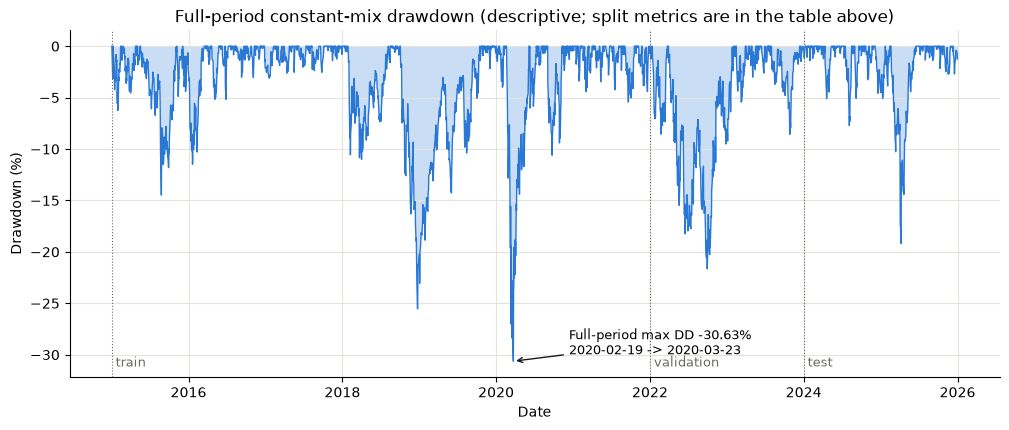

In [11]:
def drawdown_series(values):
    return values / values.cummax() - 1.0

def max_drawdown(values):
    """Max drawdown with peak, trough and recovery dates of a positive, finite value path."""
    v = np.asarray(values, dtype=float)
    if len(v) < 2:
        raise ValueError("drawdown needs at least two values")
    if not np.isfinite(v).all() or (v <= 0).any():
        raise ValueError("value path must be finite and strictly positive")
    dd = drawdown_series(values)
    mdd = float(dd.min())
    if mdd >= 0:
        return {"max_drawdown_pct": 0.0, "peak_date": None, "trough_date": None, "recovery_date": None}
    trough_pos = int(dd.to_numpy().argmin())
    before = values.iloc[: trough_pos + 1]
    peak_value = float(before.max())
    peak_pos = max(i for i, v in enumerate(before.to_numpy()) if v == peak_value)
    after = values.iloc[trough_pos + 1:]
    rec = after[after >= peak_value]
    return {"max_drawdown_pct": mdd * 100, "peak_date": values.index[peak_pos].date(),
            "trough_date": values.index[trough_pos].date(),
            "recovery_date": rec.index[0].date() if len(rec) else "not recovered"}

# Each split's path restarts at 100,000 at the close of the trading day before its first return.
SPLIT_VALUES = {name: constant_mix_value(r, CAPITAL, base_date_for(CALENDAR, r.index[0]))
                for name, r in SPLIT_RETURNS.items()}
dd_rows = [{"scope": f"{name} (split-specific)", "base_date": v.index[0].date(), "end_date": v.index[-1].date(),
            **max_drawdown(v)} for name, v in SPLIT_VALUES.items()]
dd_rows.append({"scope": "full period (descriptive only)", "base_date": portfolio_value.index[0].date(),
                "end_date": portfolio_value.index[-1].date(), **max_drawdown(portfolio_value)})
dd_table = pd.DataFrame(dd_rows)
display(dd_table.style.format({"max_drawdown_pct": "{:.2f}%"}).hide(axis="index"))

full_dd = drawdown_series(portfolio_value) * 100
worst = dd_rows[-1]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(full_dd.index, full_dd, 0, color="#2a78d6", alpha=0.25, linewidth=0)
ax.plot(full_dd.index, full_dd, color="#2a78d6", linewidth=1)
for name, (s, e) in SPLITS.items():
    ax.axvline(s, color="#6b6a63", linewidth=0.8, linestyle=":")
    ax.text(s, 0.03, f" {name}", transform=ax.get_xaxis_transform(), fontsize=9, color="#6b6a63")
ax.annotate(f"Full-period max DD {worst['max_drawdown_pct']:.2f}%\n{worst['peak_date']} -> {worst['trough_date']}",
            xy=(pd.Timestamp(worst["trough_date"]), worst["max_drawdown_pct"]), xytext=(40, 5),
            textcoords="offset points", fontsize=9, arrowprops={"arrowstyle": "->", "color": "#1a1a19"})
ax.set_ylabel("Drawdown (%)")
ax.set_xlabel("Date")
ax.set_title("Full-period constant-mix drawdown (descriptive; split metrics are in the table above)")
plt.show()

## Part 6 — Risk attribution

### 12. Euler volatility contributions (training period)
$\sigma_p=\sqrt{w^\top\Sigma w}$, $RC_i=w_i(\Sigma w)_i/\sigma_p$, $\sum_i RC_i=\sigma_p$, with $\Sigma$ the sample covariance (ddof=1) of training-period daily returns. *Standalone* asset volatility (an asset on its own) is not the same as its *contribution* to portfolio volatility (which includes its correlation with the rest). Contributions describe average day-to-day variability in the training sample; they do not by themselves explain the losses in any particular stress episode.

,AAPL,MSFT,NVDA,JPM,XOM,JNJ,WMT,CAT
AAPL,3.34e-04,2.12e-04,2.81e-04,1.43e-04,1.14e-04,8.64e-05,8.29e-05,1.43e-04
MSFT,2.12e-04,2.88e-04,2.85e-04,1.47e-04,1.11e-04,9.63e-05,8.67e-05,1.41e-04
NVDA,2.81e-04,2.85e-04,8.21e-04,1.73e-04,1.38e-04,9.38e-05,9.96e-05,1.90e-04
JPM,1.43e-04,1.47e-04,1.73e-04,3.18e-04,2.04e-04,9.35e-05,6.69e-05,2.16e-04
XOM,1.14e-04,1.11e-04,1.38e-04,2.04e-04,3.11e-04,8.30e-05,5.44e-05,2.01e-04
JNJ,8.64e-05,9.63e-05,9.38e-05,9.35e-05,8.30e-05,1.39e-04,6.43e-05,8.96e-05
WMT,8.29e-05,8.67e-05,9.96e-05,6.69e-05,5.44e-05,6.43e-05,1.81e-04,6.80e-05
CAT,1.43e-04,1.41e-04,1.90e-04,2.16e-04,2.01e-04,8.96e-05,6.80e-05,3.54e-04


,weight,mean_daily_return_contribution_pct,standalone_asset_vol_annual_pct,marginal_contribution_daily,vol_contribution_daily,vol_contribution_annual_pct,share_of_portfolio_vol_pct
AAPL,0.125,0.0161%,29.02%,0.013784,0.001723,2.74%,13.6%
MSFT,0.125,0.0167%,26.95%,0.013496,0.001687,2.68%,13.3%
NVDA,0.125,0.0343%,45.49%,0.020533,0.002567,4.07%,20.3%
JPM,0.125,0.0099%,28.33%,0.013434,0.001679,2.67%,13.3%
XOM,0.125,0.0013%,27.99%,0.012004,0.001501,2.38%,11.8%
JNJ,0.125,0.0057%,18.73%,0.007358,0.000920,1.46%,7.3%
WMT,0.125,0.0059%,21.34%,0.006940,0.000867,1.38%,6.8%
CAT,0.125,0.0094%,29.87%,0.013833,0.001729,2.74%,13.6%
TOTAL,,0.0994%,,,0.012673,20.12%,100.0%


Portfolio volatility (train): 0.012673 daily = 20.12% annualized (sqrt(w'Sigma w); equals std of portfolio returns: True)
Sum of Euler contributions:   0.012673 daily (difference 1.73e-18)


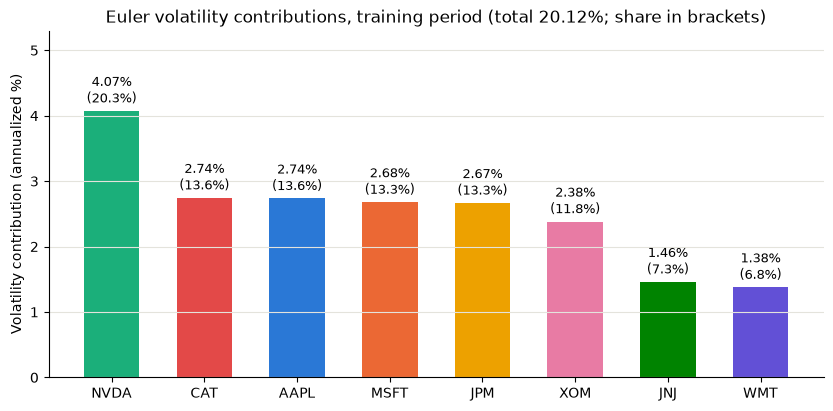

In [12]:
def euler_from_cov(cov, weights):
    """Portfolio vol, Euler contributions and marginal contributions from a labelled covariance matrix."""
    if list(cov.index) != list(cov.columns):
        raise ValueError("covariance matrix must have identical row and column labels")
    S = cov.to_numpy(dtype=float)
    if not np.isfinite(S).all() or not np.allclose(S, S.T, rtol=0, atol=1e-15):
        raise ValueError("covariance matrix must be finite and symmetric")
    wv = validate_weights(weights, assets=list(cov.columns))[list(cov.columns)].to_numpy()   # aligned by name
    sigma_w = S @ wv
    var_p = float(wv @ sigma_w)
    if var_p <= 0:
        raise ValueError("portfolio variance must be positive")
    vol = math.sqrt(var_p)
    return vol, pd.Series(wv * sigma_w / vol, index=cov.columns), pd.Series(sigma_w / vol, index=cov.columns)

def euler_contributions(asset_r, weights):
    validate_returns(asset_r)
    if len(asset_r) < 2:
        raise ValueError("covariance needs at least two observations")
    cov = asset_r.cov(ddof=1)
    return (cov, *euler_from_cov(cov, weights))

train_assets = asset_returns.loc[SPLIT_OF == "train", STOCKS]
assert train_assets.index.min() >= SPLITS["train"][0] and train_assets.index.max() <= SPLITS["train"][1], "covariance must use training data only"
cov, port_vol, rc_series, marginal = euler_contributions(train_assets, WEIGHTS)
w = WEIGHTS[STOCKS].to_numpy()
rc = rc_series[STOCKS].to_numpy()

display(cov.style.format("{:.2e}").set_caption(f"Training-period daily covariance matrix (ddof=1), {train_assets.index.min().date()} to {train_assets.index.max().date()}, n = {len(train_assets)}"))

contrib = pd.DataFrame({
    "weight": w,
    "mean_daily_return_contribution_pct": (train_assets.mean() * WEIGHTS[STOCKS]).to_numpy() * 100,
    "standalone_asset_vol_annual_pct": train_assets.std(ddof=1).to_numpy() * math.sqrt(ANN) * 100,
    "marginal_contribution_daily": marginal[STOCKS].to_numpy(),
    "vol_contribution_daily": rc,
    "vol_contribution_annual_pct": rc * math.sqrt(ANN) * 100,
    "share_of_portfolio_vol_pct": rc / port_vol * 100,
}, index=pd.Index(STOCKS, name="ticker"))
totals = contrib.sum().to_frame("TOTAL").T
totals[["weight", "standalone_asset_vol_annual_pct", "marginal_contribution_daily"]] = np.nan
display(pd.concat([contrib, totals]).style.format({
    "weight": "{:.3f}", "mean_daily_return_contribution_pct": "{:.4f}%", "standalone_asset_vol_annual_pct": "{:.2f}%",
    "marginal_contribution_daily": "{:.6f}", "vol_contribution_daily": "{:.6f}", "vol_contribution_annual_pct": "{:.2f}%",
    "share_of_portfolio_vol_pct": "{:.1f}%"}, na_rep=""))
print(f"Portfolio volatility (train): {port_vol:.6f} daily = {port_vol * math.sqrt(ANN) * 100:.2f}% annualized "
      f"(sqrt(w'Sigma w); equals std of portfolio returns: {math.isclose(port_vol, SPLIT_RETURNS['train'].std(ddof=1), rel_tol=1e-12)})")
print(f"Sum of Euler contributions:   {rc.sum():.6f} daily (difference {abs(rc.sum() - port_vol):.2e})")
assert math.isclose(rc.sum(), port_vol, rel_tol=0, abs_tol=1e-12)
assert math.isclose(port_vol, SPLIT_RETURNS["train"].std(ddof=1), rel_tol=1e-12)
shuffled = WEIGHTS[STOCKS[::-1]]                              # same weights, different order
assert np.allclose(euler_from_cov(cov, shuffled)[1][STOCKS], rc, rtol=0, atol=1e-18), "weights not aligned by name"

order = contrib.sort_values("vol_contribution_annual_pct", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(order.index, order["vol_contribution_annual_pct"], color=[STOCK_COLORS[t] for t in order.index], width=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}%\n({s:.1f}%)" for v, s in zip(order["vol_contribution_annual_pct"],
                                                                order["share_of_portfolio_vol_pct"])], padding=3, fontsize=9)
ax.set_ylabel("Volatility contribution (annualized %)")
ax.set_title(f"Euler volatility contributions, training period (total {port_vol * math.sqrt(ANN) * 100:.2f}%; share in brackets)")
ax.set_ylim(0, order["vol_contribution_annual_pct"].max() * 1.3)
ax.grid(axis="x", visible=False)
plt.show()

## Part 7 — Historical stress analysis
Five different quantities, not interchangeable: **(1)** single-day loss $-r_{p,t}$; **(2)** compounded 5-day cumulative loss $1-\prod_{j=0}^{4}(1+r_{p,t-j})$; **(3)** 5-day within-path drawdown, the peak-to-trough fall inside the window including its starting value (≥ the cumulative loss when the path dips and partly recovers); **(4)** historical VaR/CVaR, distribution estimates over a whole sample; **(5)** a limit breach, a comparison of one of these with a configured threshold. Historical worst cases are reference scenarios from this sample only, not guarantees or an exhaustive set of future stresses.

### 13. Worst days, worst 5-day windows and the metric taxonomy

(1) Five worst single days (training period, 1-day horizon):


,portfolio_return,loss_pct,"loss_USD_on_100,000"
2020-03-16,-11.0701%,11.07%,"11,070.06"
2020-03-12,-9.1956%,9.20%,"9,195.59"
2020-03-09,-8.3097%,8.31%,"8,309.70"
2020-06-11,-5.9032%,5.90%,"5,903.21"
2020-02-27,-4.9195%,4.92%,"4,919.48"


(2)+(3) Five worst non-overlapping rolling 5-day windows (training period), ranked by compounded loss:


rank,start_date,end_date,trading_days,compounded_return,loss_pct,loss_USD,within_path_drawdown_pct,worst_day_in_window,worst_day_return_pct
1,2020-03-06,2020-03-12,5,-18.4329%,18.43%,"18,432.92",18.43%,2020-03-12,-9.20%
2,2020-02-21,2020-02-27,5,-12.2100%,12.21%,"12,209.98",12.21%,2020-02-27,-4.92%
3,2020-03-16,2020-03-20,5,-11.6676%,11.67%,"11,667.57",11.67%,2020-03-16,-11.07%
4,2015-08-19,2015-08-25,5,-10.8960%,10.90%,"10,896.04",10.90%,2015-08-24,-3.62%
5,2018-02-02,2018-02-08,5,-9.2457%,9.25%,"9,245.67",9.25%,2018-02-05,-4.89%


Same windows in chronological order: 2015-08-19 to 2015-08-25, 2018-02-02 to 2018-02-08, 2020-02-21 to 2020-02-27, 2020-03-06 to 2020-03-12, 2020-03-16 to 2020-03-20


,n_days,(1) worst 1-day loss,(2) worst 5-day compounded loss,(3) worst 5-day within-path drawdown,(4) 1-day VaR 95%,(4) 1-day CVaR 95%,(4) 1-day VaR 99%,(4) 1-day CVaR 99%
period,,,,,,,,
train,1762,11.07%,18.43%,18.43%,1.86%,3.06%,3.68%,5.16%
validation,501,4.44%,9.34%,9.34%,1.93%,2.74%,3.38%,3.86%
test,502,5.93%,12.03%,12.56%,1.32%,2.20%,2.53%,3.94%


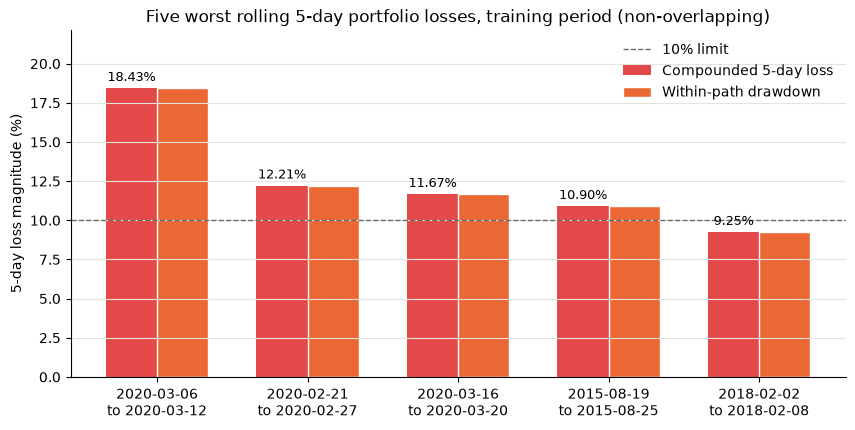

In [13]:
def rolling_compound(r, h):
    """R_h ending at t = prod_{j=0}^{h-1}(1 + r_{t-j}) - 1 (NaN until h observations exist)."""
    if not isinstance(h, (int, np.integer)) or h < 1:
        raise ValueError(f"horizon must be a positive integer, got {h!r}")
    check_return_values(r, "rolling-window input")
    return np.expm1(np.log1p(r).rolling(h, min_periods=h).sum())

def path_metrics(r_window):
    """Cumulative loss (positive) and within-path max drawdown magnitude of a return window, path starting at 1."""
    x = check_return_values(r_window, "path")
    path = np.concatenate([[1.0], np.cumprod(1.0 + x)])
    return 1.0 - path[-1], -float(np.min(path / np.maximum.accumulate(path) - 1.0))

train_rp = SPLIT_RETURNS["train"]

worst_days = train_rp.nsmallest(5).to_frame("portfolio_return")
worst_days["loss_pct"] = -worst_days["portfolio_return"] * 100
worst_days[f"loss_{CURRENCY}_on_{CAPITAL:,.0f}"] = -worst_days["portfolio_return"] * CAPITAL
worst_days.index = worst_days.index.date
print("(1) Five worst single days (training period, 1-day horizon):")
display(worst_days.style.format({"portfolio_return": "{:.4%}", "loss_pct": "{:.2f}%", f"loss_{CURRENCY}_on_{CAPITAL:,.0f}": "{:,.2f}"}))

roll5 = rolling_compound(train_rp, HORIZON)
positions = {d: i for i, d in enumerate(train_rp.index)}
taken, rows = [], []
for end_date, value in roll5.dropna().sort_values().items():   # worst first; skip windows overlapping a chosen one
    end = positions[end_date]
    start = end - HORIZON + 1
    if any(not (end < a or start > b) for a, b in taken):
        continue
    taken.append((start, end))
    window = train_rp.iloc[start:end + 1]
    loss, path_dd = path_metrics(window)
    rows.append({"rank": len(rows) + 1, "start_date": train_rp.index[start].date(), "end_date": end_date.date(),
                 "trading_days": len(window), "compounded_return": value, "loss_pct": -value * 100, f"loss_{CURRENCY}": -value * CAPITAL,
                 "within_path_drawdown_pct": path_dd * 100, "worst_day_in_window": window.idxmin().date(),
                 "worst_day_return_pct": window.min() * 100})
    if len(rows) == N_WORST:
        break
worst_windows = pd.DataFrame(rows)
assert (worst_windows["trading_days"] == HORIZON).all()
assert np.allclose(worst_windows["compounded_return"], -worst_windows["loss_pct"] / 100)
print(f"(2)+(3) Five worst non-overlapping rolling {HORIZON}-day windows (training period), ranked by compounded loss:")
display(worst_windows.style.format({"compounded_return": "{:.4%}", "loss_pct": "{:.2f}%", f"loss_{CURRENCY}": "{:,.2f}",
                                    "within_path_drawdown_pct": "{:.2f}%", "worst_day_return_pct": "{:+.2f}%"}).hide(axis="index"))
print("Same windows in chronological order:", ", ".join(f"{s} to {e}" for s, e in
      worst_windows.sort_values("start_date")[["start_date", "end_date"]].itertuples(index=False)))

taxonomy = []
for name, r in SPLIT_RETURNS.items():
    all_paths = [path_metrics(r.iloc[i - HORIZON + 1: i + 1]) for i in range(HORIZON - 1, len(r))]
    taxonomy.append({"period": name, "n_days": len(r),
                     "(1) worst 1-day loss": -r.min(),
                     f"(2) worst {HORIZON}-day compounded loss": max(p[0] for p in all_paths),
                     f"(3) worst {HORIZON}-day within-path drawdown": max(p[1] for p in all_paths),
                     "(4) 1-day VaR 95%": historical_var(r, 0.95), "(4) 1-day CVaR 95%": historical_cvar(r, 0.95),
                     "(4) 1-day VaR 99%": historical_var(r, 0.99), "(4) 1-day CVaR 99%": historical_cvar(r, 0.99)})
taxonomy_df = pd.DataFrame(taxonomy).set_index("period")
display(taxonomy_df.style.format({c: "{:.2%}" for c in taxonomy_df.columns if c != "n_days"})
        .set_caption("Loss magnitudes (positive = loss) by metric and period; (5) limit breaches follow in Part 8"))

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = [f"{s:%Y-%m-%d}\nto {e:%Y-%m-%d}" for s, e in zip(worst_windows["start_date"], worst_windows["end_date"])]
x = np.arange(len(labels))
bars = ax.bar(x - 0.17, worst_windows["loss_pct"], color="#e34948", width=0.34, label="Compounded 5-day loss")
ax.bar(x + 0.17, worst_windows["within_path_drawdown_pct"], color="#eb6834", width=0.34, label="Within-path drawdown",
       edgecolor="white", linewidth=1)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in worst_windows["loss_pct"]], padding=3, fontsize=9)
ax.axhline(10, color="#6b6a63", linestyle="--", linewidth=1, label="10% limit")
ax.set_xticks(x, labels)
ax.set_ylabel(f"{HORIZON}-day loss magnitude (%)")
ax.set_title(f"Five worst rolling {HORIZON}-day portfolio losses, training period (non-overlapping)")
ax.set_ylim(0, worst_windows[["loss_pct", "within_path_drawdown_pct"]].max().max() * 1.2)
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

## Part 8 — Risk-limit evaluation

### 14. Risk-limit checks
Experimental project thresholds from `config/default.toml`, not regulatory standards. Breach rule `>=`: breach if observed ≥ threshold − 1e-12. 1-day limits (VaR, CVaR) are compared with 1-day estimates; 5-day limits with the worst 5-day path in the period. The training window is the configured estimation window; validation and test rows are out-of-sample monitoring.

In [14]:
LIMITS = risk_cfg.get("limits") or [   # fallback only if the config has no limits
    {"name": "stress_loss_5d", "metric": "cumulative_loss", "horizon_days": 5, "threshold": 0.10, "breach_rule": ">="},
    {"name": "stress_drawdown_5d", "metric": "max_drawdown", "horizon_days": 5, "threshold": 0.10, "breach_rule": ">="},
    {"name": "historical_var_95_1d", "metric": "historical_var", "horizon_days": 1, "confidence": 0.95, "threshold": 0.03, "breach_rule": ">="},
    {"name": "historical_cvar_95_1d", "metric": "historical_cvar", "horizon_days": 1, "confidence": 0.95, "threshold": 0.06, "breach_rule": ">="},
]
RISK_METRICS = ("cumulative_loss", "max_drawdown", "historical_var", "historical_cvar")
LIMIT_SOURCE = "config/default.toml [[risk.limits]]" if risk_cfg.get("limits") else "illustrative fallback"

for lim in LIMITS:
    if lim["breach_rule"] not in (">=", ">") or not 0 < lim["threshold"] < 1 or lim["metric"] not in RISK_METRICS:
        raise ValueError(f"invalid limit specification: {lim}")

def worst_5d_path_metrics(r, h):
    """Worst cumulative loss and worst within-path drawdown over all rolling h-day windows (path starts at V0)."""
    if len(r) < h:
        raise ValueError(f"need at least {h} returns for {h}-day windows")
    worst_loss, worst_dd, loss_end, dd_end = -np.inf, -np.inf, None, None
    for end in range(h - 1, len(r)):
        loss, dd = path_metrics(r.iloc[end - h + 1: end + 1])
        if loss > worst_loss:
            worst_loss, loss_end = loss, r.index[end]
        if dd > worst_dd:
            worst_dd, dd_end = dd, r.index[end]
    return worst_loss, worst_dd, loss_end, dd_end

def is_breach(observed, threshold, rule, tol=TOL):
    """'>=': observed >= threshold - tol; '>': observed > threshold + tol. NaN observations cannot be judged."""
    if not math.isfinite(observed):
        raise ValueError("cannot evaluate a limit on a non-finite observation")
    if rule == ">=":
        return observed >= threshold - tol
    if rule == ">":
        return observed > threshold + tol
    raise ValueError(f"unknown breach rule {rule!r}")

limit_rows = []
for name, r in SPLIT_RETURNS.items():
    wl, wd, wl_end, wd_end = worst_5d_path_metrics(r, HORIZON)
    for lim in LIMITS:
        if lim["metric"] == "cumulative_loss":
            obs, note = wl, f"worst rolling window ending {wl_end.date()}"
        elif lim["metric"] == "max_drawdown":
            obs, note = wd, f"worst rolling window ending {wd_end.date()}"
        elif lim["metric"] == "historical_var":
            obs, note = historical_var(r, lim["confidence"]), f"{lim['confidence']:.0%} historical, {len(r)} obs"
        elif lim["metric"] == "historical_cvar":
            obs, note = historical_cvar(r, lim["confidence"]), f"{lim['confidence']:.0%} historical, {len(r)} obs"
        else:
            obs, note = float("nan"), "metric not supported here"
        limit_rows.append({
            "period": name + (" (estimation window)" if name == risk_cfg["estimation_window"] else ""),
            "limit": lim["name"], "metric": lim["metric"], "horizon": f"{lim['horizon_days']} day" + ("s" if lim["horizon_days"] > 1 else ""),
            "threshold_pct": lim["threshold"] * 100, "observed_pct": obs * 100,
            "status": "not evaluated" if not math.isfinite(obs) else ("BREACH" if is_breach(obs, lim["threshold"], lim["breach_rule"]) else "within limit"),
            "rule": f"observed {lim['breach_rule']} threshold",
            "observation": note,
        })
limit_table = pd.DataFrame(limit_rows)
print("Limit source:", LIMIT_SOURCE)
display(limit_table.style.format({"threshold_pct": "{:.2f}%", "observed_pct": "{:.2f}%"}).hide(axis="index").map(
    lambda v: "color: #e34948; font-weight: bold" if v == "BREACH" else ("color: #008300" if v == "within limit" else ""),
    subset=["status"]))
print("1-day metrics: historical VaR/CVaR of daily returns. 5-day metrics: worst compounded loss and worst "
      "within-path drawdown over every rolling 5-trading-day window of the period.")

Limit source: config/default.toml [[risk.limits]]


period,limit,metric,horizon,threshold_pct,observed_pct,status,rule,observation
train (estimation window),stress_loss_5d,cumulative_loss,5 days,10.00%,18.43%,BREACH,observed >= threshold,worst rolling window ending 2020-03-12
train (estimation window),stress_drawdown_5d,max_drawdown,5 days,10.00%,18.43%,BREACH,observed >= threshold,worst rolling window ending 2020-03-12
train (estimation window),historical_var_95_1d,historical_var,1 day,3.00%,1.86%,within limit,observed >= threshold,"95% historical, 1762 obs"
train (estimation window),historical_cvar_95_1d,historical_cvar,1 day,6.00%,3.06%,within limit,observed >= threshold,"95% historical, 1762 obs"
validation,stress_loss_5d,cumulative_loss,5 days,10.00%,9.34%,within limit,observed >= threshold,worst rolling window ending 2022-06-14
validation,stress_drawdown_5d,max_drawdown,5 days,10.00%,9.34%,within limit,observed >= threshold,worst rolling window ending 2022-06-14
validation,historical_var_95_1d,historical_var,1 day,3.00%,1.93%,within limit,observed >= threshold,"95% historical, 501 obs"
validation,historical_cvar_95_1d,historical_cvar,1 day,6.00%,2.74%,within limit,observed >= threshold,"95% historical, 501 obs"
test,stress_loss_5d,cumulative_loss,5 days,10.00%,12.03%,BREACH,observed >= threshold,worst rolling window ending 2025-04-08
test,stress_drawdown_5d,max_drawdown,5 days,10.00%,12.56%,BREACH,observed >= threshold,worst rolling window ending 2025-04-09


1-day metrics: historical VaR/CVaR of daily returns. 5-day metrics: worst compounded loss and worst within-path drawdown over every rolling 5-trading-day window of the period.


## Part 9 — Validation and reconciliation

### 15. Final validation (real data and engine reconciliation)

In [15]:
results = []

def check(name, fn):
    try:
        ok, detail = bool(fn()), ""
    except Exception as exc:
        ok, detail = False, f"{type(exc).__name__}: {exc}"
    results.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

check("Weights sum to 1 (tol 1e-8)", lambda: abs(WEIGHTS.sum() - 1) <= 1e-8)
check("Weighted portfolio returns correct (row-wise w'r)",
      lambda: np.allclose(portfolio_returns.to_numpy(), asset_returns[STOCKS].to_numpy() @ w, rtol=0, atol=1e-15))
check("Constant-mix value: V_t / V_(t-1) - 1 = r_p,t",
      lambda: np.allclose(portfolio_value.to_numpy()[1:] / portfolio_value.to_numpy()[:-1] - 1, portfolio_returns.to_numpy(), atol=1e-12))
check("Value path starts at initial capital", lambda: portfolio_value.iloc[0] == CAPITAL and buy_hold_value.iloc[0] == CAPITAL)
check("Buy-and-hold holdings: h_i,t = w_i V_0 prod(1 + r_i)",
      lambda: np.allclose(bh[STOCKS].iloc[-1].to_numpy(), w * CAPITAL * (1 + asset_returns[STOCKS]).prod().to_numpy(), rtol=1e-12))
check("VaR/CVaR finite for every split (n >= min_observations)",
      lambda: all(len(r) >= MIN_OBS for r in SPLIT_RETURNS.values()) and np.isfinite(risk_table[["VaR_pct", "CVaR_pct"]]).all().all())
check("CVaR >= VaR (tol 1e-12)", lambda: (risk_table["CVaR_pct"] / 100 >= risk_table["VaR_pct"] / 100 - TOL).all())
check("VaR equals numpy inverted_cdf quantile",
      lambda: all(math.isclose(historical_var(r, a), -np.quantile(r, 1 - a, method="inverted_cdf"), abs_tol=1e-15)
                  for r in SPLIT_RETURNS.values() for a in CONFIDENCES))
check("Drawdown never positive", lambda: (drawdown_series(portfolio_value) <= 0).all()
      and all((drawdown_series(v) <= 0).all() for v in SPLIT_VALUES.values()))
check("Euler contributions sum to portfolio volatility", lambda: math.isclose(rc.sum(), port_vol, abs_tol=1e-12))
check("Missing returns not replaced with zero",
      lambda: len(asset_returns) == int(asset_returns_all.notna().all(axis=1).sum()) and not asset_returns.isna().any().any()
      and returns[STOCK_COLS].isna().any(axis=1).sum() == len(removed))
check("Splits chronologically separated",
      lambda: SPLIT_RETURNS["train"].index.max() < SPLIT_RETURNS["validation"].index.min()
      and SPLIT_RETURNS["validation"].index.max() < SPLIT_RETURNS["test"].index.min())
check("Each split inside its configured dates",
      lambda: all(SPLITS[n][0] <= r.index.min() and r.index.max() <= SPLITS[n][1] for n, r in SPLIT_RETURNS.items()))

# Cross-check against the existing Stage 3 engine outputs (results/stage3, written by src/rlstress).
ref = json.loads((STAGE3_RESULTS / "historical_risk_metrics.json").read_text())["windows"]
ref_contrib = pd.read_csv(STAGE3_RESULTS / "asset_risk_contributions.csv", index_col="ticker")
ref_value = pd.read_csv(STAGE3_RESULTS / "portfolio_value.csv", parse_dates=["date"], index_col="date")

def matches_reference(window, r):
    vr, cr = {x["confidence"]: x["var_pct"] for x in ref[window]["var"]}, {x["confidence"]: x["cvar_pct"] for x in ref[window]["cvar"]}
    return all(math.isclose(historical_var(r, a), vr[a], abs_tol=1e-15) and math.isclose(historical_cvar(r, a), cr[a], abs_tol=1e-15)
               for a in CONFIDENCES)

check("Train VaR/CVaR match results/stage3", lambda: matches_reference("train", SPLIT_RETURNS["train"]))
check("Full-sample VaR/CVaR match results/stage3", lambda: matches_reference("full_sample", portfolio_returns))
check("Train max drawdown matches results/stage3",
      lambda: math.isclose(dd_table.iloc[0]["max_drawdown_pct"] / 100, ref["train"]["max_drawdown"]["max_drawdown"], abs_tol=1e-12))
check("Euler contributions match results/stage3",
      lambda: np.allclose(contrib["vol_contribution_daily"], ref_contrib.loc[STOCKS, "vol_contribution_daily"], atol=1e-15))
check("Value paths match results/stage3",
      lambda: np.allclose(portfolio_value, ref_value["portfolio_value_constant_mix"].reindex(portfolio_value.index), rtol=1e-12)
      and np.allclose(buy_hold_value, ref_value["portfolio_value_buy_and_hold"].reindex(buy_hold_value.index), rtol=1e-12))

# Stage 2 provenance: the returns used here are the same data the risk engine reads (risk.returns_path).
engine_input = pd.read_csv(PROJECT_ROOT / risk_cfg["returns_path"], parse_dates=["date"], index_col="date")
check("Stage 2 returns identical to risk-engine input (" + risk_cfg["returns_path"] + ")",
      lambda: returns.index.equals(engine_input.index) and returns[STOCK_COLS].equals(engine_input[STOCK_COLS]))

validation_df = pd.DataFrame(results)
display(validation_df.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""),
    subset=["result"]))
for r in results:
    print(f"{r['result']}  {r['check']}" + (f"  ({r['detail']})" if r["detail"] else ""))
n_pass = sum(r["result"] == "PASS" for r in results)
print(f"\n{n_pass}/{len(results)} checks PASS")
assert n_pass == len(results), "validation failed"
print("Final validation complete (synthetic tests and baseline reproducibility follow)")

check,result,detail
Weights sum to 1 (tol 1e-8),PASS,
Weighted portfolio returns correct (row-wise w'r),PASS,
"Constant-mix value: V_t / V_(t-1) - 1 = r_p,t",PASS,
Value path starts at initial capital,PASS,
"Buy-and-hold holdings: h_i,t = w_i V_0 prod(1 + r_i)",PASS,
VaR/CVaR finite for every split (n >= min_observations),PASS,
CVaR >= VaR (tol 1e-12),PASS,
VaR equals numpy inverted_cdf quantile,PASS,
Drawdown never positive,PASS,
Euler contributions sum to portfolio volatility,PASS,


PASS  Weights sum to 1 (tol 1e-8)
PASS  Weighted portfolio returns correct (row-wise w'r)
PASS  Constant-mix value: V_t / V_(t-1) - 1 = r_p,t
PASS  Value path starts at initial capital
PASS  Buy-and-hold holdings: h_i,t = w_i V_0 prod(1 + r_i)
PASS  VaR/CVaR finite for every split (n >= min_observations)
PASS  CVaR >= VaR (tol 1e-12)
PASS  VaR equals numpy inverted_cdf quantile
PASS  Drawdown never positive
PASS  Euler contributions sum to portfolio volatility
PASS  Missing returns not replaced with zero
PASS  Splits chronologically separated
PASS  Each split inside its configured dates
PASS  Train VaR/CVaR match results/stage3
PASS  Full-sample VaR/CVaR match results/stage3
PASS  Train max drawdown matches results/stage3
PASS  Euler contributions match results/stage3
PASS  Value paths match results/stage3
PASS  Stage 2 returns identical to risk-engine input (data/processed/features/consolidated_daily.csv)

19/19 checks PASS
Final validation complete (synthetic tests and baseline repro

### 16. Valuation audit: synthetic tests and independent reproduction

In [16]:
audit = []
def audit_check(name, fn):
    try:
        ok, detail = fn()
    except Exception as exc:
        ok, detail = False, f"{type(exc).__name__}: {exc}"
    audit.append({"test": name, "result": "PASS" if ok else "FAIL", "detail": detail})

def raises(fn):
    try:
        fn()
    except ValueError:
        return True
    return False

# Hand-calculable example: 2 assets, w = (0.5, 0.5), V0 = 100.
# Day 1: (+10%, -10%) -> r_p = 0       CM 100.00   BH (55, 45) = 100
# Day 2: (+20%,   0%) -> r_p = 0.10    CM 110.00   BH (66, 45) = 111, final weights 66/111, 45/111
d0, d1, d2 = pd.Timestamp("2020-01-02"), pd.Timestamp("2020-01-03"), pd.Timestamp("2020-01-06")
syn_r = pd.DataFrame({"A": [0.10, 0.20], "B": [-0.10, 0.0]}, index=pd.DatetimeIndex([d1, d2]))
syn_w = pd.Series({"A": 0.5, "B": 0.5})
syn_rp = (syn_r * syn_w).sum(axis=1)
syn_cm = constant_mix_value(syn_rp, 100.0, d0)
syn_bh = buy_and_hold_value(syn_r, syn_w, 100.0, d0)

audit_check("initial value = capital at base date (both strategies)",
            lambda: (syn_cm.iloc[0] == 100 and syn_bh["total"].iloc[0] == 100 and syn_cm.index[0] == d0, f"CM {syn_cm.iloc[0]}, BH {syn_bh['total'].iloc[0]} at {d0.date()}"))
audit_check("first-day return applied exactly once",
            lambda: (math.isclose(syn_cm.loc[d1], 100.0) and np.allclose(syn_bh.loc[d1, ["A", "B"]], [55, 45]) and len(syn_cm) == 3,
                     f"V(day1) = {syn_cm.loc[d1]:.2f}; holdings {syn_bh.loc[d1, ['A', 'B']].tolist()}; 3 values for 2 returns"))
audit_check("constant mix: daily compounding of the weighted return",
            lambda: (math.isclose(syn_cm.iloc[-1], 110.0, rel_tol=1e-15), f"final {syn_cm.iloc[-1]:.10f} (expected 110)"))
audit_check("constant mix rebalances: r_p,t = w' r_t every day",
            lambda: (np.allclose(syn_rp.to_numpy(), [0.0, 0.10]), f"r_p = {syn_rp.round(10).tolist()}"))
audit_check("buy and hold: holdings compound independently, total = sum",
            lambda: (np.allclose(syn_bh.iloc[-1][["A", "B"]], [66, 45]) and math.isclose(syn_bh["total"].iloc[-1], 111.0), f"holdings {syn_bh.iloc[-1][['A', 'B']].tolist()}, total {syn_bh['total'].iloc[-1]:.10f}"))
audit_check("buy and hold final weights = holding / total, sum to 1",
            lambda: (np.allclose(syn_bh.iloc[-1][["A", "B"]] / syn_bh["total"].iloc[-1], [66 / 111, 45 / 111]), "66/111, 45/111"))
audit_check("base date must precede first return (no double application)",
            lambda: (raises(lambda: constant_mix_value(syn_rp, 100.0, d1)) and base_date_for(pd.DatetimeIndex([d0, d1, d2]), d1) == d0
                     and raises(lambda: base_date_for(pd.DatetimeIndex([d1, d2]), d1)), "base = d1 rejected; prior calendar date found; missing prior date raises"))
bad_inputs = {
    "NaN": syn_rp.where(syn_rp.index != d2),
    "infinity": pd.Series([0.0, np.inf], index=syn_rp.index),
    "below -100%": pd.Series([0.0, -1.5], index=syn_rp.index),
    "duplicate dates": pd.Series([0.0, 0.1], index=pd.DatetimeIndex([d1, d1])),
    "unsorted dates": syn_rp.iloc[::-1],
}
audit_check("invalid returns and dates are rejected (CM and BH)",
            lambda: (all(raises(lambda s=s: constant_mix_value(s, 100.0, d0)) for s in bad_inputs.values())
                     and raises(lambda: buy_and_hold_value(syn_r.assign(B=[np.nan, 0.0]), syn_w, 100.0, d0))
                     and raises(lambda: buy_and_hold_value(syn_r[["A"]], syn_w, 100.0, d0)), "rejected: " + ", ".join(bad_inputs) + ", NaN holding, missing holding"))
# Corporate action example: a 10-for-1 split on unadjusted prices looks like a -90% day; adjusted prices do not.
unadj = pd.Series([1000.0, 101.0])
adj_px = pd.Series([100.0, 101.0])
audit_check("split handling: unadjusted split = -90% artefact, adjusted = +1%; real data uses adjusted",
            lambda: (math.isclose(unadj.pct_change().iloc[-1], -0.899) and math.isclose(adj_px.pct_change().iloc[-1], 0.01)
                     and provenance_checks["split-day returns all below 5% (no unadjusted split jumps)"], "real split-day |r| max "
                     f"{prov['max_abs_return_on_split_days'].max():.2%}"))

# Independent reproduction on real data, by a different route: raw prices only, no cumulative products of returns.
growth = raw_adj.iloc[-1] / raw_adj.iloc[0]                       # P_T / P_0 per stock
bh_independent = float((WEIGHTS[STOCKS] * CAPITAL * growth[STOCKS]).sum())
cm_independent = CAPITAL * float(np.exp(np.log1p(raw_adj.pct_change(fill_method=None).iloc[1:].to_numpy() @ WEIGHTS[STOCKS].to_numpy()).sum()))
audit_check("buy and hold final = sum_i w_i V0 P_i,T / P_i,0 (raw prices)",
            lambda: (math.isclose(buy_hold_value.iloc[-1], bh_independent, rel_tol=1e-12), f"notebook {buy_hold_value.iloc[-1]:,.2f} vs independent {bh_independent:,.2f}"))
audit_check("constant mix final = V0 exp(sum log(1 + w'r_t)) (raw prices)",
            lambda: (math.isclose(portfolio_value.iloc[-1], cm_independent, rel_tol=1e-10), f"notebook {portfolio_value.iloc[-1]:,.2f} vs independent {cm_independent:,.2f}"))
audit_check("total returns consistent with values",
            lambda: (np.allclose(summary_values["total_return_pct"], [(portfolio_value.iloc[-1] / CAPITAL - 1) * 100, (bh_independent / CAPITAL - 1) * 100], rtol=1e-10),
                     f"CM {summary_values['total_return_pct'][0]:,.2f}%, BH {summary_values['total_return_pct'][1]:,.2f}%"))
audit_check("both paths: same dates, unique, n_returns + 1 values",
            lambda: (portfolio_value.index.equals(bh.index) and portfolio_value.index.is_unique and len(bh) == len(asset_returns) + 1 == 2766,
                     f"{len(portfolio_value)} values, {BASE_DATE.date()} -> {portfolio_value.index[-1].date()}"))
ref_value = pd.read_csv(STAGE3_RESULTS / "portfolio_value.csv", parse_dates=["date"], index_col="date")
audit_check("agreement with results/stage3/portfolio_value.csv (risk engine)",
            lambda: (ref_value.index.equals(portfolio_value.index)
                     and np.allclose(ref_value["portfolio_value_constant_mix"], portfolio_value, rtol=1e-12)
                     and np.allclose(ref_value["portfolio_value_buy_and_hold"], buy_hold_value, rtol=1e-12),
                     f"engine final CM {ref_value['portfolio_value_constant_mix'].iloc[-1]:,.2f}, BH {ref_value['portfolio_value_buy_and_hold'].iloc[-1]:,.2f}"))

# Existing project tests for returns, portfolio valuation and the Stage 3 engine (separate process).
import subprocess, sys
proc = subprocess.run([sys.executable, "-m", "pytest", "tests/test_returns.py", "tests/test_portfolio.py", "tests/test_risk_metrics.py",
                       "tests/test_risk_engine_integration.py", "-q", "--color=no", "-p", "no:cacheprovider"],
                      cwd=PROJECT_ROOT, capture_output=True, text=True)
audit.append({"test": "existing tests: returns, portfolio, risk metrics, risk engine", "result": "PASS" if proc.returncode == 0 else "FAIL",
              "detail": (proc.stdout.strip().splitlines() or ["no output"])[-1]})

audit_df = pd.DataFrame(audit)
display(audit_df.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
n_ok = int((audit_df["result"] == "PASS").sum())
print(f"{n_ok}/{len(audit_df)} valuation audit tests PASS")
assert n_ok == len(audit_df), "valuation audit failed"

test,result,detail
initial value = capital at base date (both strategies),PASS,"CM 100.0, BH 100.0 at 2020-01-02"
first-day return applied exactly once,PASS,"V(day1) = 100.00; holdings [55.00000000000001, 45.0]; 3 values for 2 returns"
constant mix: daily compounding of the weighted return,PASS,final 110.0000000000 (expected 110)
"constant mix rebalances: r_p,t = w' r_t every day",PASS,"r_p = [0.0, 0.1]"
"buy and hold: holdings compound independently, total = sum",PASS,"holdings [66.0, 45.0], total 111.0000000000"
"buy and hold final weights = holding / total, sum to 1",PASS,"66/111, 45/111"
base date must precede first return (no double application),PASS,base = d1 rejected; prior calendar date found; missing prior date raises
invalid returns and dates are rejected (CM and BH),PASS,"rejected: NaN, infinity, below -100%, duplicate dates, unsorted dates, NaN holding, missing holding"
"split handling: unadjusted split = -90% artefact, adjusted = +1%; real data uses adjusted",PASS,real split-day |r| max 3.39%
"buy and hold final = sum_i w_i V0 P_i,T / P_i,0 (raw prices)",PASS,"notebook 5,427,439.87 vs independent 5,427,439.87"


15/15 valuation audit tests PASS


### 17. Synthetic risk-metric and input-validation tests
Hand-calculable examples, independent of the market data.

In [17]:
risk_tests = []
def rt(name, fn):
    try:
        ok, detail = fn()
    except Exception as exc:
        ok, detail = False, f"{type(exc).__name__}: {exc}"
    risk_tests.append({"test": name, "result": "PASS" if ok else "FAIL", "detail": detail})

def raises_value_error(fn):
    try:
        fn()
    except ValueError:
        return True
    return False

dates = lambda n: pd.bdate_range("2020-01-02", periods=n)

# VaR / CVaR. Returns -0.001, -0.002, ..., -0.100 (n = 100). 95%: m = 5, k = 5 -> VaR = 0.096, CVaR = mean(0.100..0.096) = 0.098.
lin = pd.Series(-np.arange(1, 101) / 1000, index=dates(100))
rt("VaR/CVaR 95% on -0.001..-0.100 (n=100)", lambda: (math.isclose(historical_var(lin, 0.95, 1), 0.096) and math.isclose(historical_cvar(lin, 0.95, 1), 0.098),
   f"VaR {historical_var(lin, 0.95, 1):.4f} (0.096), CVaR {historical_cvar(lin, 0.95, 1):.4f} (0.098)"))
rt("VaR/CVaR 99%: m = 1 -> both equal the single worst loss", lambda: (math.isclose(historical_var(lin, 0.99, 1), 0.1) and math.isclose(historical_cvar(lin, 0.99, 1), 0.1), "0.100 / 0.100"))
# Fractional tail: n = 30, alpha 0.95 -> m = 1.5, j = 1, boundary 0.5: CVaR = (0.06 + 0.5 * 0.03) / 1.5 = 0.05; VaR = -r_(2) = 0.03.
frac = pd.Series([-0.06, -0.03] + [0.0] * 28, index=dates(30))
rt("CVaR fractional boundary weight (m = 1.5)", lambda: (math.isclose(historical_cvar(frac, 0.95, 1), 0.05) and math.isclose(historical_var(frac, 0.95, 1), 0.03),
   f"CVaR {historical_cvar(frac, 0.95, 1):.4f} (0.05), VaR {historical_var(frac, 0.95, 1):.4f} (0.03)"))
rt("CVaR >= VaR on 1,000 random series", lambda: (all(historical_cvar(s, a, 1) >= historical_var(s, a, 1) - 1e-15
   for s in [pd.Series(np.random.default_rng(i).standard_t(3, 257) * 0.01, index=dates(257)) for i in range(500)] for a in (0.95, 0.99)), "500 series x 2 levels"))
rt("VaR refused below min_observations; invalid alpha / NaN / inf rejected",
   lambda: (math.isnan(historical_var(lin.iloc[:10], 0.95)) and math.isnan(historical_cvar(lin.iloc[:10], 0.95))
            and raises_value_error(lambda: historical_var(lin, 1.0, 1)) and raises_value_error(lambda: historical_var(lin, 0.0, 1))
            and raises_value_error(lambda: historical_var(lin.where(lin.index != lin.index[3]), 0.95, 1))
            and raises_value_error(lambda: historical_cvar(lin.replace(-0.05, -np.inf), 0.95, 1)), "n=10 < 250 -> NaN; alpha 0/1, NaN, -inf raise"))
rt("VaR of an all-gain series is negative (not clipped)", lambda: (historical_var(pd.Series([0.01, 0.02, 0.03], index=dates(3)), 0.5, 1) == -0.02, "VaR50 = -0.02"))

# Drawdown on a known path: 100, 120, 90, 95, 130, 117 -> -25% from 120 (day 1) to 90 (day 2), recovered on day 4.
path = pd.Series([100, 120, 90, 95, 130, 117], index=dates(6), dtype=float)
dd = max_drawdown(path)
rt("max drawdown on known path", lambda: (math.isclose(dd["max_drawdown_pct"], -25.0) and dd["peak_date"] == path.index[1].date()
   and dd["trough_date"] == path.index[2].date() and dd["recovery_date"] == path.index[4].date(), f"{dd['max_drawdown_pct']:.2f}%, peak {dd['peak_date']}, trough {dd['trough_date']}, recovery {dd['recovery_date']}"))
rt("drawdown: unrecovered path, rising path, invalid paths", lambda: (
   max_drawdown(pd.Series([100.0, 80.0, 90.0], index=dates(3)))["recovery_date"] == "not recovered"
   and max_drawdown(pd.Series([100.0, 101.0, 102.0], index=dates(3)))["max_drawdown_pct"] == 0.0
   and raises_value_error(lambda: max_drawdown(pd.Series([100.0], index=dates(1))))
   and raises_value_error(lambda: max_drawdown(pd.Series([100.0, 0.0], index=dates(2))))
   and raises_value_error(lambda: max_drawdown(pd.Series([100.0, np.nan], index=dates(2)))), "-20% not recovered; 0% for rising; 1 point / zero / NaN rejected"))

# Rolling compounding and path metrics: (1.1)(0.9) - 1 = -0.01; path 1 -> 1.1 -> 0.99: loss 1%, drawdown 10%.
rt("rolling compounded return", lambda: (np.allclose(rolling_compound(pd.Series([0.1, -0.1, 0.1], index=dates(3)), 2).to_numpy(), [np.nan, -0.01, -0.01], equal_nan=True)
   and raises_value_error(lambda: rolling_compound(pd.Series([0.1], index=dates(1)), 0)), "[nan, -0.01, -0.01]; h = 0 rejected"))
rt("path metrics: cumulative loss vs within-path drawdown", lambda: (np.allclose(path_metrics([0.10, -0.10]), [0.01, 0.10]) and np.allclose(path_metrics([-0.05, -0.05]), [0.0975, 0.0975]),
   "+10%/-10%: loss 1%, drawdown 10%; -5%/-5%: both 9.75%"))

# Annualized volatility: std([0.01, -0.01], ddof=1) = 0.0141421 -> x sqrt(252).
rt("annualized volatility", lambda: (math.isclose(annualized_volatility(pd.Series([0.01, -0.01])), math.sqrt(2) * 0.01 * math.sqrt(252))
   and raises_value_error(lambda: annualized_volatility(pd.Series([0.01]))), f"{annualized_volatility(pd.Series([0.01, -0.01])):.6f}; 1 observation rejected"))

# Euler: sd 10% and 20%, corr 0.5, w = (0.5, 0.5): Sigma w = (0.01, 0.025), sigma_p = sqrt(0.0175), RC = (0.005, 0.0125) / sigma_p.
cov2 = pd.DataFrame([[0.01, 0.01], [0.01, 0.04]], index=["A", "B"], columns=["A", "B"])
vol2, rc2, _ = euler_from_cov(cov2, pd.Series({"B": 0.5, "A": 0.5}))
rt("Euler contributions: closed form, sum, name alignment", lambda: (math.isclose(vol2, math.sqrt(0.0175)) and np.allclose(rc2[["A", "B"]], [0.005 / vol2, 0.0125 / vol2])
   and math.isclose(rc2.sum(), vol2), f"sigma_p {vol2:.6f}; RC A {rc2['A']:.6f}, B {rc2['B']:.6f}; weights given in reverse order"))
rt("Euler rejects misaligned or invalid inputs", lambda: (raises_value_error(lambda: euler_from_cov(cov2, pd.Series({"A": 0.5, "C": 0.5})))
   and raises_value_error(lambda: euler_from_cov(cov2.iloc[:, ::-1], pd.Series({"A": 0.5, "B": 0.5})))
   and raises_value_error(lambda: euler_from_cov(pd.DataFrame([[0.01, 0.02], [0.0, 0.04]], index=["A", "B"], columns=["A", "B"]), pd.Series({"A": 0.5, "B": 0.5}))),
   "unknown ticker, label mismatch, asymmetric matrix rejected"))

# Risk-limit boundary (rule '>=', tolerance 1e-12).
rt("limit boundary: equality breaches, tolerance only absorbs float error", lambda: (
   is_breach(0.10, 0.10, ">=") and is_breach(0.10 - 5e-13, 0.10, ">=") and not is_breach(0.10 - 1e-9, 0.10, ">=")
   and not is_breach(0.10, 0.10, ">") and is_breach(0.10 + 1e-9, 0.10, ">") and is_breach(0.1 + 0.2 - 0.2, 0.1, ">=")
   and raises_value_error(lambda: is_breach(float("nan"), 0.1, ">=")) and raises_value_error(lambda: is_breach(0.2, 0.1, "<")),
   "0.10 >= 0.10 breach; 0.10 - 5e-13 breach; 0.10 - 1e-9 no; '>' at equality no; NaN / unknown rule rejected"))

# Portfolio inputs.
rt("weights: negative, sum != 1, NaN, duplicate, misaligned rejected", lambda: (all(raises_value_error(lambda w_=w_: validate_weights(w_, assets=["A", "B"])) for w_ in [
   pd.Series({"A": 1.2, "B": -0.2}), pd.Series({"A": 0.5, "B": 0.4}), pd.Series({"A": np.nan, "B": 1.0}),
   pd.Series([0.5, 0.5], index=["A", "A"]), pd.Series({"A": 0.5, "C": 0.5})]), "5/5 invalid weight vectors rejected"))
rt("capital: zero, negative, infinite, NaN, text rejected", lambda: (all(raises_value_error(lambda c=c: validate_capital(c)) for c in [0, -1, np.inf, np.nan, "abc"]), "5/5 rejected"))
rt("valuation rejects invalid weights and capital", lambda: (
   raises_value_error(lambda: buy_and_hold_value(syn_r, pd.Series({"A": 0.7, "B": 0.7}), 100.0, d0))
   and raises_value_error(lambda: constant_mix_value(syn_rp, 0.0, d0)) and raises_value_error(lambda: buy_and_hold_value(syn_r, syn_w, -5.0, d0))
   and raises_value_error(lambda: base_date_for(pd.DatetimeIndex([d1, d0]), d2)), "weights sum 1.4, capital 0 / -5, unsorted calendar"))
rt("portfolio return: weights aligned by ticker name", lambda: (np.allclose(portfolio_daily_returns(syn_r, pd.Series({"B": 0.5, "A": 0.5})), [0.0, 0.10]), "r_p = [0.0, 0.1]"))
rt("integrity report flags duplicate, unsorted, inf, < -100%, partial gaps", lambda: (
   (lambda bad: (~integrity_report(bad, ["x_return", "y_return"]).set_index("check")["pass"]).sum() >= 5)(
       pd.DataFrame({"x_return": [0.01, np.inf, -1.5, np.nan], "y_return": [0.0, 0.01, 0.02, 0.03]},
                    index=pd.DatetimeIndex(["2020-01-03", "2020-01-02", "2020-01-02", "2020-01-06"]))), "duplicate, unsorted, inf, -150%, partial NaN all flagged"))

risk_tests_df = pd.DataFrame(risk_tests)
display(risk_tests_df.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
print(f"{(risk_tests_df['result'] == 'PASS').sum()}/{len(risk_tests_df)} synthetic risk-metric tests PASS")
assert (risk_tests_df["result"] == "PASS").all()

test,result,detail
VaR/CVaR 95% on -0.001..-0.100 (n=100),PASS,"VaR 0.0960 (0.096), CVaR 0.0980 (0.098)"
VaR/CVaR 99%: m = 1 -> both equal the single worst loss,PASS,0.100 / 0.100
CVaR fractional boundary weight (m = 1.5),PASS,"CVaR 0.0500 (0.05), VaR 0.0300 (0.03)"
"CVaR >= VaR on 1,000 random series",PASS,500 series x 2 levels
VaR refused below min_observations; invalid alpha / NaN / inf rejected,PASS,"n=10 < 250 -> NaN; alpha 0/1, NaN, -inf raise"
VaR of an all-gain series is negative (not clipped),PASS,VaR50 = -0.02
max drawdown on known path,PASS,"-25.00%, peak 2020-01-03, trough 2020-01-06, recovery 2020-01-08"
"drawdown: unrecovered path, rising path, invalid paths",PASS,-20% not recovered; 0% for rising; 1 point / zero / NaN rejected
rolling compounded return,PASS,"[nan, -0.01, -0.01]; h = 0 rejected"
path metrics: cumulative loss vs within-path drawdown,PASS,"+10%/-10%: loss 1%, drawdown 10%; -5%/-5%: both 9.75%"


19/19 synthetic risk-metric tests PASS


### 18. Baseline reproducibility
Headline results recorded from the pre-upgrade notebook (backup `backups/stage_3_pre_upgrade_2026-10-24.ipynb`, run 2026-10-24). The upgrade must reproduce them exactly.

In [18]:
BASELINE = {
 "cm_final": 1286726.6378244546,
 "bh_final": 5427439.87039312,
 "vol": {
  "train": 20.117267656232197,
  "validation": 19.97913709609061,
  "test": 15.83443993696446
 },
 "var_cvar": {
  "train_95%": [
   1.8625856902120077,
   3.0612844674820274
  ],
  "train_99%": [
   3.676360433165951,
   5.156735875611864
  ],
  "validation_95%": [
   1.928768364127945,
   2.7449660266004043
  ],
  "validation_99%": [
   3.3787872381584725,
   3.864697090856632
  ],
  "test_95%": [
   1.3203421869684937,
   2.202853676586407
  ],
  "test_99%": [
   2.5333855267106715,
   3.9367293405389776
  ]
 },
 "mdd": {
  "train (split-specific)": [
   -30.631325048982138,
   "2020-02-19",
   "2020-03-23",
   "2020-06-05"
  ],
  "validation (split-specific)": [
   -21.6510936741216,
   "2022-03-30",
   "2022-09-30",
   "2023-02-02"
  ],
  "test (split-specific)": [
   -19.191710679948592,
   "2025-02-19",
   "2025-04-08",
   "2025-06-20"
  ],
  "full period (descriptive only)": [
   -30.631325048982138,
   "2020-02-19",
   "2020-03-23",
   "2020-06-05"
  ]
 },
 "port_vol_train": 0.012672687446788957,
 "rc": {
  "AAPL": 0.0017229843310908014,
  "MSFT": 0.0016869968994440428,
  "NVDA": 0.002566574272328842,
  "JPM": 0.0016791905748685576,
  "XOM": 0.0015005301958171712,
  "JNJ": 0.0009197959801805148,
  "WMT": 0.0008674642745912354,
  "CAT": 0.001729150918467792
 },
 "worst_windows": [
  [
   "2020-03-06",
   "2020-03-12",
   -0.18432923388690034
  ],
  [
   "2020-02-21",
   "2020-02-27",
   -0.12209979404394804
  ],
  [
   "2020-03-16",
   "2020-03-20",
   -0.11667565645538276
  ],
  [
   "2015-08-19",
   "2015-08-25",
   -0.10896037082711824
  ],
  [
   "2018-02-02",
   "2018-02-08",
   -0.09245666198493914
  ]
 ],
 "limits": [
  [
   "train (estimation window)",
   "stress_loss_5d",
   18.432923388690035,
   "BREACH"
  ],
  [
   "train (estimation window)",
   "stress_drawdown_5d",
   18.432923388690035,
   "BREACH"
  ],
  [
   "train (estimation window)",
   "historical_var_95_1d",
   1.8625856902120077,
   "within limit"
  ],
  [
   "train (estimation window)",
   "historical_cvar_95_1d",
   3.0612844674820274,
   "within limit"
  ],
  [
   "validation",
   "stress_loss_5d",
   9.343976955909405,
   "within limit"
  ],
  [
   "validation",
   "stress_drawdown_5d",
   9.343976955909405,
   "within limit"
  ],
  [
   "validation",
   "historical_var_95_1d",
   1.928768364127945,
   "within limit"
  ],
  [
   "validation",
   "historical_cvar_95_1d",
   2.7449660266004043,
   "within limit"
  ],
  [
   "test",
   "stress_loss_5d",
   12.032522397699951,
   "BREACH"
  ],
  [
   "test",
   "stress_drawdown_5d",
   12.555265744850196,
   "BREACH"
  ],
  [
   "test",
   "historical_var_95_1d",
   1.3203421869684937,
   "within limit"
  ],
  [
   "test",
   "historical_cvar_95_1d",
   2.202853676586407,
   "within limit"
  ]
 ]
}

repro = []
def rep(name, ok, detail):
    repro.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

rep("constant-mix final value", math.isclose(portfolio_value.iloc[-1], BASELINE["cm_final"], rel_tol=1e-12), f"{portfolio_value.iloc[-1]:,.2f} vs {BASELINE['cm_final']:,.2f}")
rep("buy-and-hold final value", math.isclose(buy_hold_value.iloc[-1], BASELINE["bh_final"], rel_tol=1e-12), f"{buy_hold_value.iloc[-1]:,.2f} vs {BASELINE['bh_final']:,.2f}")
rep("annualized volatility (3 splits)", all(math.isclose(r["annual_vol_pct"], BASELINE["vol"][r["period"]], rel_tol=1e-12) for r in vol_table.to_dict("records")), "train / validation / test")
rep("VaR and CVaR (3 splits x 2 levels)", all(np.allclose([r["VaR_pct"], r["CVaR_pct"]], BASELINE["var_cvar"][f"{r['period']}_{r['confidence']}"], rtol=1e-12)
    for r in risk_table.to_dict("records")), "12 values")
rep("max drawdown and dates (4 scopes)", all(math.isclose(r["max_drawdown_pct"], BASELINE["mdd"][r["scope"]][0], rel_tol=1e-12)
    and [str(r["peak_date"]), str(r["trough_date"]), str(r["recovery_date"])] == BASELINE["mdd"][r["scope"]][1:] for r in dd_table.to_dict("records")), "train / validation / test / full")
rep("Euler contributions and portfolio vol", math.isclose(port_vol, BASELINE["port_vol_train"], rel_tol=1e-12)
    and np.allclose(rc, [BASELINE["rc"][t] for t in STOCKS], rtol=1e-12), f"sigma_p {port_vol:.10f}")
rep("worst 5-day windows (dates and returns)", [[str(r["start_date"]), str(r["end_date"])] for r in worst_windows.to_dict("records")] == [x[:2] for x in BASELINE["worst_windows"]]
    and np.allclose(worst_windows["compounded_return"], [x[2] for x in BASELINE["worst_windows"]], rtol=1e-12), "5 windows")
rep("risk-limit observations and statuses (12 rows)", [[r["period"], r["limit"], r["status"]] for r in limit_table.to_dict("records")] == [[x[0], x[1], x[3]] for x in BASELINE["limits"]]
    and np.allclose(limit_table["observed_pct"], [x[2] for x in BASELINE["limits"]], rtol=1e-12), "12 rows")
again = constant_mix_value(portfolio_daily_returns(asset_returns[STOCKS], WEIGHTS), CAPITAL, BASE_DATE)
rep("deterministic recomputation", again.equals(portfolio_value), "value path recomputed from scratch is bit-identical")

repro_df = pd.DataFrame(repro)
display(repro_df.style.hide(axis="index").map(
    lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))

total = len(results) + len(audit) + len(risk_tests) + len(repro) + len(provenance_checks) + len(integrity)
passed = (sum(r["result"] == "PASS" for r in results) + sum(a["result"] == "PASS" for a in audit) + sum(r["result"] == "PASS" for r in risk_tests)
          + sum(r["result"] == "PASS" for r in repro) + sum(provenance_checks.values()) + int(integrity["pass"].sum()))
print(f"Validation summary: integrity {int(integrity['pass'].sum())}/{len(integrity)}, provenance {sum(provenance_checks.values())}/{len(provenance_checks)}, "
      f"final validation {sum(r['result'] == 'PASS' for r in results)}/{len(results)}, valuation audit {sum(a['result'] == 'PASS' for a in audit)}/{len(audit)}, "
      f"synthetic risk tests {sum(r['result'] == 'PASS' for r in risk_tests)}/{len(risk_tests)}, baseline {sum(r['result'] == 'PASS' for r in repro)}/{len(repro)}")
print(f"TOTAL {passed}/{total} checks PASS")
assert passed == total
print("STAGE 3 COMPLETE")

check,result,detail
constant-mix final value,PASS,"1,286,726.64 vs 1,286,726.64"
buy-and-hold final value,PASS,"5,427,439.87 vs 5,427,439.87"
annualized volatility (3 splits),PASS,train / validation / test
VaR and CVaR (3 splits x 2 levels),PASS,12 values
max drawdown and dates (4 scopes),PASS,train / validation / test / full
Euler contributions and portfolio vol,PASS,sigma_p 0.0126726874
worst 5-day windows (dates and returns),PASS,5 windows
risk-limit observations and statuses (12 rows),PASS,12 rows
deterministic recomputation,PASS,value path recomputed from scratch is bit-identical


Validation summary: integrity 8/8, provenance 8/8, final validation 19/19, valuation audit 15/15, synthetic risk tests 19/19, baseline 9/9
TOTAL 78/78 checks PASS
STAGE 3 COMPLETE


## Part 10 — Limitations and interpretation
- **Historical, not predictive.** VaR, CVaR, drawdowns and worst windows describe 2015–2025 only. Validation and test figures rest on about 500 days each (≈5 tail observations at 99%), so those tail estimates are imprecise.
- **Data source.** One source (Yahoo Finance adjusted closes, downloaded 2026-10-18). Adjustment factors, dividend reinvestment at the ex-date close and absence of withholding tax are assumed, not independently verified; Yahoo may restate history.
- **Selection with hindsight.** The eight stocks are large, surviving companies chosen today; NVDA alone grew 386× in this sample, so buy-and-hold results are not representative of a randomly chosen portfolio.
- **Frictionless accounting.** Constant mix assumes free daily rebalancing at closing prices; buy and hold assumes no costs either. Real implementations would pay costs and taxes.
- **Path limits.** The 5-day limits are evaluated on historical windows here; Stage 4 applies the same definitions to simulated paths. Thresholds are experimental project settings, not regulatory standards.
- **Attribution.** Euler contributions are a variance decomposition of average daily volatility in the training sample, not an explanation of any specific loss.